# Parejas ideales de pádel

**Objetivo:** encontrar las parejas que maximizan la probabilidad de ganar el torneo según su estilo de juego. Esto se quiere lograr en 4 fases:
1. Manejo de datos
2. Modelos predictivos
3. Distribuciones
4. Simulación de parejas

Las decisiones estrategicas tomadas para realizar el proyecto se encuentran en el acrivho README como `D#`. Las cuatro generales son: D1 (cómo está armado este notebook), D2 (solo se escribe lo que los datos demuestran), D3 (ningún partido tiene reglas especiales) y D4 (qué va en cada archivo).

**Glosario:**
1. *frame* = una foto del video
2. *track* = el seguimiento de una persona dentro de un punto
3. *fondo* = mitad de la cancha de cada equipo (BOTTOM, cerca de la cámara; TOP, lejos)
4. *lado* = LEFT o RIGHT
5. *código* = código de estudiante de 6 dígitos, la llave que une las fuentes.

## Configuración

In [1]:
# Recarga src/ cada vez que cambia, sin reiniciar el kernel
%load_ext autoreload
%autoreload 2

import sys
import time
import warnings
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from skopt.space import Integer, Real, Categorical

from src import datos, fuentes
from src import distribuciones as dis
from src import identidades as idn
from src import modelo as mod
from src import variables as var
from src import video as vid

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
COLOR = '#2a78d6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.axisbelow': True, 'axes.prop_cycle': plt.cycler(color=[COLOR]), 'axes.titlelocation': 'left',
                     'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8})

## Fase 1 — Manejo de datos

se trabajan los datos a nivel frame × jugador de los cuales se saca jugador × punto para despues agrupar en equipo × punto

### 1.1 Entendimiento de los datos

**Objetivo:** saber qué es cada fila de las tres fuentes y qué tipo y unidad tiene cada columna.

Usamos 3 fuentes:
- **Video** (`video/partido_XX.parquet`): cada fila es un jugador en un frame.
- **Traza** (`Traza_Partidos_202602.xlsx`, hojas `CANCHA_1` y `CANCHA_2`): cada fila es un punto.
- **Formulario** (`Datos_Jugadores_Padel_202602.xlsx`): cada fila es un jugador.

Los datos originales están en `data/raw/` y no se cambian (D5). El video llega ya procesado; no se corre el programa de visión del profesor (D6).

**Unidades de las varibales del video**
- Posición (`player_position_x`, `player_position_y`) y distancia a la red (`distance_player_to_net_m`): en metros. La cancha mide 10 × 20 m y la red está en `y` = 10.
- Velocidad y aceleración del jugador: m/s y m/s².
- Puntos del cuerpo y de la raqueta (`head_x` … `racket_tip_y`) y sus velocidades (`racket_speed`, `wrist_speed`, `elbow_speed`): en píxeles y píxeles por segundo.
- `body_scale`: en píxeles. Es la distancia entre la cabeza y el hombro en la imagen.
- Ángulos y velocidades de giro (`*_angular_velocity`): grados y grados por segundo.
- Columnas de sí/no (`pose_available`, `racket_above_shoulder`, `wrist_above_head`, `*_implausible`): vienen como texto `True`/`False`.
- `team`, `zone`, `racket_direction` y los nombres: texto.
- Pelota (`ball_*`): metros y m/s.

**Traza:** quién ganó el punto (`PUNTO_EQUIPO_1`, 0/1; es lo que se quiere predecir, D7), el marcador, los nombres de los 4 jugadores, el fondo (TOP/BOTTOM) y el lado (LEFT/RIGHT).

**Formulario:** `CODIGO_ESTUDIANTE`, `EDAD` (años), `ESTATURA` (cm), `TALLA` (peso en kg, D8) y respuestas en texto (nivel, experiencia, estado físico, etc.).

In [2]:
traza_cruda = datos.leer_traza()
form_crudo = datos.leer_formulario()
tipos_video = datos.tipos_video()
video = datos.leer_video(vid.COLUMNAS_IDENTIDAD)

display(pd.DataFrame({
    'una fila es': ['un jugador en un frame', 'un punto', 'un jugador'],
    'filas': [len(video), len(traza_cruda), len(form_crudo)],
    'columnas': [len(tipos_video), traza_cruda.shape[1], form_crudo.shape[1]],
    'partidos': [video['partido'].nunique(), traza_cruda['ID_PARTIDO'].nunique(), '—'],
    'puntos': [len(video[['partido', 'punto']].drop_duplicates()), len(traza_cruda), '—'],
}, index=['video', 'traza', 'formulario']))
print('Tipos de las columnas del video:', tipos_video.value_counts().to_dict())
print('Columnas de texto del video:', tipos_video[tipos_video == 'string'].index.tolist())

,una fila es,filas,columnas,partidos,puntos
video,un jugador en un frame,718936,74,27,272
traza,un punto,283,20,27,283
formulario,un jugador,29,30,—,—


Tipos de las columnas del video: {'double': 57, 'string': 11, 'int64': 5, 'bool': 1}
Columnas de texto del video: ['player_name', 'team', 'zone', 'racket_direction', 'wrist_above_head', 'racket_above_shoulder', 'pose_available', 'player_speed_implausible', 'ball_speed_implausible', 'row_implausible', 'nombre_norm']


In [3]:
# Columnas sí/no del video: llegan como texto porque tienen vacíos
sino = datos.leer_video(['pose_available', 'racket_above_shoulder', 'wrist_above_head', 'team', 'body_scale'])
display(pd.DataFrame({c: sino[c].value_counts(dropna=False) for c in ['pose_available', 'racket_above_shoulder', 'wrist_above_head']}))

# body_scale: qué tan grande se ve el jugador en la imagen, según su fondo
display(sino.groupby('team')['body_scale'].describe()[['count', 'min', '50%', 'max']].round(1))
del sino

,pose_available,racket_above_shoulder,wrist_above_head
False,117674,550877,569274
True,577098,11299,21
<NA>,24164,156760,149641


,count,min,50%,max
team,,,,
bottom,299736.0,4.6,70.0,227.8
top,237977.0,3.1,29.7,79.1


In [4]:
print(f"Objetivo (D7): el equipo 1 gana el {traza_cruda['PUNTO_EQUIPO_1'].mean():.1%} de los puntos.",
      'Fondo del equipo 1:', traza_cruda['EQUIPO_1_POSICION'].value_counts().to_dict())
display(form_crudo[['EDAD', 'ESTATURA', 'TALLA']].describe().T.round(1))
for c in ['GENERO', 'NIVEL_ACTUAL_PADEL', 'TIEMPO_JUGANDO_PADEL', 'EXPERIENCIA_PADEL', 'PRACTICA_OTRO_DEPORTE_RAQUETA',
          'ESTADO_FISICO', 'FRECUENCIA_DEPORTE']:
    print(f'{c}:', form_crudo[c].value_counts().to_dict())

Objetivo (D7): el equipo 1 gana el 43.1% de los puntos. Fondo del equipo 1: {'BOTTOM': 283}


,count,mean,std,min,25%,50%,75%,max
EDAD,29.0,20.3,2.9,18.0,19.0,19.0,21.0,30.0
ESTATURA,29.0,171.8,11.9,150.0,165.0,173.0,179.0,194.0
TALLA,29.0,69.1,16.7,40.0,60.0,69.0,80.0,107.0


GENERO: {'Masculino': 18, 'Femenino': 11}
NIVEL_ACTUAL_PADEL: {'Principiante': 12, 'Primera vez': 11, 'Intermedio': 5, 'Avanzado': 1}
TIEMPO_JUGANDO_PADEL: {'Menos de 6 meses': 22, 'Entre 6 meses y 1 año': 5, 'Más de 1 año': 2}
EXPERIENCIA_PADEL: {'No': 16, 'Sí': 13}
PRACTICA_OTRO_DEPORTE_RAQUETA: {'No': 14, 'Tenis': 9, 'Tenis de mesa': 3, 'Squash': 2, 'Otro': 1}
ESTADO_FISICO: {'Bueno': 19, 'Excelente': 5, 'Regular': 4, 'Malo': 1}
FRECUENCIA_DEPORTE: {'Más de 4 veces': 9, '1-2 veces': 9, '3-4 veces': 7, '0 veces': 3, 'No practico deportes': 1}


**Resultados**
- El video tiene 718.936 filas × 74 columnas de 27 partidos y 272 puntos (57 columnas con decimales, 11 de texto, 5 de enteros y 1 de sí/no). La traza tiene 283 puntos de esos 27 partidos y el formulario, 29 jugadores × 30 columnas.
- **Columnas de sí/no guardadas como texto:** `pose_available`, `racket_above_shoulder`, `wrist_above_head` y las `*_implausible` llegan como texto `True`/`False` porque tienen vacíos (una columna de sí/no no acepta vacíos). `racket_above_shoulder` es verdadera en 11.299 frames (1,6 %) y `wrist_above_head` solo en 21.
- **`body_scale`:** es la distancia cabeza–hombro en píxeles. Su mediana es 70 px en BOTTOM y 30 px en TOP: lejos de la cámara el jugador se ve 2,4 veces más pequeño, así que todo lo que se mide en píxeles cambia según el fondo. Solo sirve para dividir las medidas en píxeles, que no se usan.
- **Formulario:** el 79 % de los jugadores es principiante o juega por primera vez.

### 1.2 Datos faltantes, atípicos y tratamiento

**Objetivo:** ver qué falta o está mal en cada fuente y decidir si se quita, se imputa o se corrige.

**Decisiones**

Formulario:
- 3 jugadores de la traza no lo llenaron: se imputan con los datos de los jugadores de su mismo sexo (D9).
- Se quitan `RITMO_CARDIACO` (le falta el 59 %) y las preguntas que no describen al jugador (ciudad, programa, desayuno, música, comentarios…).
- Se quitan `Puntos_Total`, `Partidos_Jugados` y `Puntos_Por_Partido`, porque son el resultado (fuga).
- Los nombres se escriben distinto en cada fuente: todo nombre se cambia por el código de 6 dígitos del estudiante (D10, D11).
- Las respuestas en texto (nivel, tiempo jugando, experiencia, estado físico y frecuencia de deporte) se pasan a números, de menor a mayor empezando en 0 (D12).

Traza:
- No le falta nada; solo se corrige el error `RIGTH` → `RIGHT` (D13).

Video:
- Se quita la pelota: la mayoría de sus posiciones son de relleno (D14).
- Se quitan la pose y la raqueta (D15, ver 1.3) y las columnas `*_implausible` y `schema_version`.
- Si un punto está repetido, se deja el de menor número (D16).
- Los tracks sin nombre o con un nombre equivocado se asignan según la posición que dice la traza; si no se puede, se quitan (D17, D18).
- Se quitan los puntos que no están en la traza (D19).
- Si en un punto la `y` es igual a la `x`, la `y` se deja vacía (D3).
- La velocidad y la aceleración traen valores imposibles: se suaviza la posición (promedio de 0,5 s) y se vuelven a calcular; lo que pase de 8 m/s o de 10 m/s² se borra, y los huecos de hasta 5 frames se rellenan (D20).

In [5]:
print('Formulario: columnas con vacíos')
display(datos.perfil_columnas(form_crudo).query('faltantes > 0'))
print('Traza: celdas vacías =', int(traza_cruda.isna().sum().sum()))
print('Video: % de filas vacías por familia de columnas')
display(vid.faltantes_por_familia())
print('Pelota: cómo se obtuvo su posición en cada frame (D14)')
display(vid.clasificar_frames_pelota(datos.leer_video(vid.COLUMNAS_PELOTA)))

Formulario: columnas con vacíos


,tipo,no_nulos,faltantes,pct_faltante,distintos
columna,,,,,
RITMO_CARDIACO,object,12,17,58.62,12
COMENTARIOS,object,28,1,3.45,24
Puntos_Total,float64,27,2,6.90,21
Partidos_Jugados,float64,27,2,6.90,5
Puntos_Por_Partido,float64,27,2,6.90,24


Traza: celdas vacías = 0
Video: % de filas vacías por familia de columnas


,columnas,pct_vacio_min,pct_vacio_max,tratamiento
identificación y tiempo,10,0.0,8.3,Usar; `team` sale de la traza
posición y movimiento,11,0.0,3.0,Limpiar y recalcular (D20)
pose y raqueta,39,3.4,24.8,Eliminar (D15)
pelota,11,0.0,90.0,Eliminar (D14)
controles de plausibilidad,3,90.0,90.0,Eliminar


Pelota: cómo se obtuvo su posición en cada frame (D14)


,frames,pct
quieta (relleno),91925,50.5
posible detección,71543,39.3
tramo recto (interpolada),18417,10.1


In [6]:
codigos = idn.tabla_codigos(form_crudo)
nombres_traza = pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
equivalencias = idn.tabla_equivalencias(
    {'formulario': form_crudo['NOMBRE'], 'traza': nombres_traza, 'video': video['nombre_norm'].unique()}, codigos)
print('Nombres por tipo de cruce:', equivalencias['tipo_cruce'].value_counts().to_dict(),
      '| sin código:', len(idn.sin_cruzar(equivalencias)))

jugadores = fuentes.agregar_derivadas_jugadores(
    fuentes.imputar_sin_formulario(fuentes.limpiar_formulario(form_crudo), datos.SEMILLA))
print('Jugadores imputados (D9):')
display(jugadores.loc[jugadores['imputado'], ['codigo', 'nombre', 'genero', 'edad', 'estatura_cm', 'peso_kg', 'nivel_padel']])

print('Controles de la traza (filas con problema):', fuentes.validar_traza(traza_cruda)['filas con problema'].to_dict())
traza = fuentes.limpiar_traza(traza_cruda, codigos)
participaciones = fuentes.traza_larga(traza)

Nombres por tipo de cruce: {'exacto': 76, 'alias': 13} | sin código: 0
Jugadores imputados (D9):


,codigo,nombre,genero,edad,estatura_cm,peso_kg,nivel_padel
0,407710,Alejandra Briget Deza Céspedes,Femenino,19,162,40.0,1
18,356629,Juan Pablo Vanegas Herrera,Masculino,20,179,76.8,1
22,324764,Laura Sofía Rodríguez González,Femenino,24,165,51.9,1


Controles de la traza (filas con problema): {'PUNTO_EQUIPO_1 + PUNTO_EQUIPO_2 != 1': 0, 'partido-punto duplicado': 0, 'MARCADOR distinto del acumulado': 0, 'ID_PUNTO no consecutivo': 0, 'lado LEFT/RIGHT cambia dentro del partido': 0}


In [7]:
diagnostico = vid.diagnosticar_puntos(video)
tracks = vid.resumir_tracks(video, diagnostico)
metodo = vid.concordancia_por_partido(tracks, participaciones, diagnostico)
identidades = vid.asignar_identidades(tracks, participaciones, diagnostico, metodo)
puntos = vid.tabla_puntos(fuentes.tabla_puntos_traza(traza), diagnostico, identidades)
participaciones = vid.enlazar_participaciones(participaciones, identidades)

print('Partidos con identidad por posición (D17):', metodo.loc[metodo['metodo'] == 'posicion', 'partido'].tolist())
print('Puntos con y = x (D3):', int(diagnostico['y_invalida'].sum()),
      '| partido:', diagnostico.loc[diagnostico['y_invalida'], 'partido'].unique().tolist())
display(identidades.groupby(['conservar', 'motivo'], dropna=False).agg(tracks=('filas', 'size'), filas=('filas', 'sum')))
print('Puntos de la traza:', int(puntos['en_traza'].sum()),
      '| con video:', int((puntos['estado_video'] == 'disponible').sum()),
      '| con los 4 jugadores identificados:', int(puntos['equipos_completos'].sum()))

Partidos con identidad por posición (D17): [8, 17, 34]
Puntos con y = x (D3): 9 | partido: [17]


tracks   filas
conservar motivo                                      
False     punto sin traza                   16    4044
          sin casilla libre compatible      47    3300
          track genérico sin identidad     105    3772
          video duplicado del punto 9        4    1932
True      NaN                             1029  705888

Puntos de la traza: 283 | con video: 267 | con los 4 jugadores identificados: 244


Cambio de y entre frames más frecuente (m: % de frames): {0.0: 66.2, 0.049: 18.4, 0.098: 2.4}
Velocidad cruda más frecuente (m/s: % de frames): {0.0: 58.9, 2.93: 7.8, 2.92: 5.3}


,p50,p99,máx,% vacío
velocidad cruda (m/s),0.00,10.68,1155.66,0.15
velocidad limpia (m/s),0.37,4.45,8.00,4.33
|aceleración| cruda (m/s²),1.74,701.24,69094.98,0.30
|aceleración| limpia (m/s²),0.30,6.49,10.00,4.44


Frames corregidos: posición 0.7 % | velocidad o aceleración 0.7 %


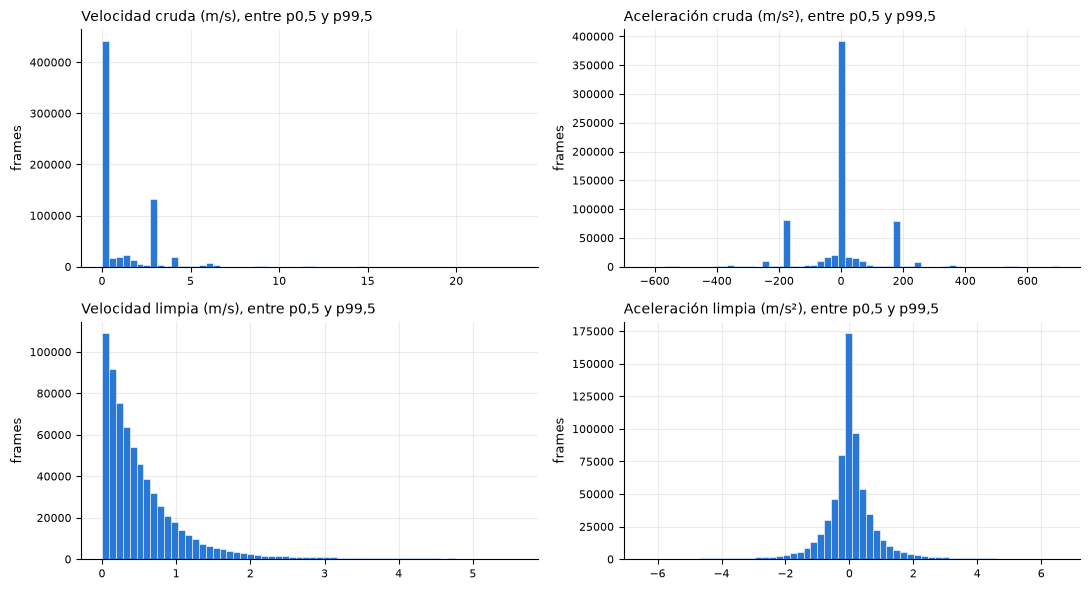

In [8]:
crudo = datos.leer_video(vid.COLUMNAS_LIMPIEZA + ['player_speed_mps', 'player_acceleration_mps2'])
video_limpio = vid.limpiar_video(crudo, identidades, diagnostico)
antes = crudo.merge(identidades.loc[identidades['conservar'], vid.LLAVE_TRACK], on=vid.LLAVE_TRACK)

# ¿Por qué no sirven la velocidad y la aceleración crudas? La posición cambia a saltos
paso_y = antes.sort_values([*vid.LLAVE_TRACK, 'frame_idx']).groupby(vid.LLAVE_TRACK)['player_position_y'].diff().abs()
print('Cambio de y entre frames más frecuente (m: % de frames):',
      (100 * paso_y.round(3).value_counts(normalize=True)).head(3).round(1).to_dict())
print('Velocidad cruda más frecuente (m/s: % de frames):',
      (100 * antes['player_speed_mps'].round(2).value_counts(normalize=True)).head(3).round(1).to_dict())

def rango(s):
    a = s.abs()
    return {'p50': a.median(), 'p99': a.quantile(0.99), 'máx': a.max(), '% vacío': 100 * a.isna().mean()}

display(pd.DataFrame({
    'velocidad cruda (m/s)': rango(antes['player_speed_mps']),
    'velocidad limpia (m/s)': rango(video_limpio['velocidad_mps']),
    '|aceleración| cruda (m/s²)': rango(antes['player_acceleration_mps2']),
    '|aceleración| limpia (m/s²)': rango(video_limpio['aceleracion_mps2']),
}).T.round(2))
print(f"Frames corregidos: posición {100 * video_limpio['posicion_corregida'].mean():.1f} % | "
      f"velocidad o aceleración {100 * video_limpio['cinematica_corregida'].mean():.1f} %")

fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
series = [(antes['player_speed_mps'], 'Velocidad cruda (m/s)'), (antes['player_acceleration_mps2'], 'Aceleración cruda (m/s²)'),
          (video_limpio['velocidad_mps'], 'Velocidad limpia (m/s)'), (video_limpio['aceleracion_mps2'], 'Aceleración limpia (m/s²)')]
for eje, (s, titulo) in zip(ejes.flat, series):
    lo, hi = s.quantile([0.005, 0.995])
    eje.hist(s[s.between(lo, hi)], bins=60, edgecolor='white', linewidth=0.4)
    eje.set_title(f'{titulo}, entre p0,5 y p99,5')
    eje.set_ylabel('frames')
fig.tight_layout()
plt.show()
del crudo, antes, paso_y

In [9]:
for nombre, tabla in [('equivalencias_nombres', equivalencias), ('jugadores', jugadores),
                      ('identidades_video', identidades), ('puntos', puntos)]:
    print('Guardado:', datos.guardar_tabla(tabla, nombre).relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(video_limpio, 'video_limpio', formato='parquet').relative_to(RAIZ))

Guardado: data\interim\equivalencias_nombres.csv
Guardado: data\interim\jugadores.csv
Guardado: data\interim\identidades_video.csv
Guardado: data\interim\puntos.csv


Guardado: data\interim\video_limpio.parquet


**Resultados**
- **Faltantes:** al formulario solo le faltan datos en `RITMO_CARDIACO` (59 %), `COMENTARIOS` y las 3 columnas de fuga; a la traza no le falta nada. En el video faltan la pose y la raqueta (del 3 al 25 %), la pelota (hasta el 90 %) y los controles (90 %); la posición está casi completa (falta como mucho el 3 %).
- **Pelota:** el 50,5 % de sus posiciones son de relleno (la pelota aparece quieta) y el 10,1 % son líneas rectas entre dos detecciones.
- **Nombres y tracks:** los 89 nombres de las tres fuentes quedaron con código (76 iguales y 13 por variantes del nombre). En los partidos 8, 17 y 34 los jugadores se asignan por posición. Quedan 1.029 tracks (705.888 frames).
- **Puntos:** 283 en la traza, 267 con video y 244 con los 4 jugadores identificados.
- **Por qué no sirven la velocidad y la aceleración que trae el video:** la posición se mueve a saltos: en el 66 % de los frames no cambia y en el 18 % salta 0,049 m. Por eso la velocidad casi solo vale 0 o 2,93 m/s (0,049 m × 60 fps) y la aceleración salta entre 0 y ±176 m/s². Esos son los picos de los histogramas de arriba.
- **Después de limpiar:** la velocidad tiene mediana 0,37 m/s y máximo 8 m/s (antes llegaba a 1.156 m/s) y la aceleración queda entre −10 y 10 m/s². Se corrigió el 0,7 % de las posiciones y el 0,7 % de las velocidades.
- **La aceleración limpia sale pareja a los dos lados del 0** porque lo que un jugador acelera en un punto también lo frena: su promedio en un punto es (velocidad final − velocidad inicial) / duración.

### 1.3 Selección preliminar de variables

**Objetivo:** con lo que queda después de la 1.2, escoger pocas variables por jugador × punto que se entiendan fácil, en 3 grupos.

**Decisiones**
- **D21 (3 grupos):**
  - *Nivel de juego* (formulario): `nivel_padel` (primera vez, principiante o intermedio/avanzado), `tiempo_jugando_padel` (0 = menos de 6 meses, 1 = 6 meses o más), `experiencia_padel` (0/1) y `practica_otra_raqueta` (0/1).
  - *Tipo de juego* (video): `atacante` (0/1), `dist_red_m` (m), `vel_media_mps` (m/s) y `pct_quieto` (%).
  - *Atributos físicos* (formulario): `estatura_cm`, `imc`, `edad`, `estado_fisico` (malo/regular, bueno o excelente), `frecuencia_deporte` (0, 1–2, 3–4 o más de 4 veces por semana) y `mujer` (0/1).
- **One-hot (D21, por recomendación del profesor):** las tres variables con más de dos categorías (`nivel_padel`, `estado_fisico` y `frecuencia_deporte`) se pasan a columnas 0/1, una por categoría, con `pd.get_dummies(drop_first=True)` como en su notebook de árboles. La primera categoría queda como base. Las de dos categorías ya son 0/1. Se mantienen las categorías unidas de una sola persona (nivel avanzado con intermedio y estado físico malo con regular).
- **Mínimo (D21):** si el track dura menos de 2 s, ese jugador no tiene variables de video en ese punto.
- **D22 (cada jugador se compara con los de su mismo fondo):** atacante = pasa al menos la mitad del punto más cerca de la red que el jugador típico (la mediana) de su fondo; quieto = va más lento que la mediana de su fondo; a `dist_red_m` y `vel_media_mps` se les resta la mediana de su fondo. La prueba está en la primera celda.
- **D23 (lo que no se usa):**
  - La pose y la raqueta (raqueta sobre el hombro, muñeca sobre la cabeza, giro de la raqueta…): les falta del 3 al 25 % de los frames, casi nunca son verdaderas (1.1) y cambian según el fondo y según qué tan grande se ve la raqueta (D15, primera celda).
  - Las velocidades de raqueta, muñeca y codo: están en píxeles y cambian según qué tan lejos esté el jugador de la cámara (1.1).
  - La aceleración: su promedio en un punto es (velocidad final − velocidad inicial) / duración, así que no dice nada del jugador.
  - Las columnas `_x`/`_y` y `body_scale`: solo sirven para calcular otras.
  - La pelota (D14).
  - Los puntos ganados: es lo que se quiere predecir (fuga).

In [10]:
# ¿Cambian las variables con el fondo? Mismos jugadores en TOP y en BOTTOM, sin corregir
sin_corregir = var.variables_video(video_limpio, por_fondo=False)
raqueta = (datos.leer_video(['player_id', 'racket_above_shoulder', 'racket_angular_velocity', 'racket_length_visible'])
           .merge(identidades.loc[identidades['conservar'], [*vid.LLAVE_TRACK, 'codigo', 'fondo']], on=vid.LLAVE_TRACK))
raqueta['raqueta_sobre_hombro'] = raqueta['racket_above_shoulder'].map({'True': 100, 'False': 0})
raqueta['giro_raqueta'] = raqueta['racket_angular_velocity'].abs()
g = raqueta.groupby([*var.LLAVE_JP, 'fondo'])
raqueta_punto = pd.DataFrame({'pct_raqueta_hombro': g['raqueta_sobre_hombro'].mean(),
                              'giro_raqueta_p90': g['giro_raqueta'].quantile(0.9)}).reset_index()
display(var.efecto_fondo(sin_corregir.merge(raqueta_punto, on=[*var.LLAVE_JP, 'fondo'], how='outer'),
                         [*var.VARIABLES_VIDEO, 'pct_raqueta_hombro', 'giro_raqueta_p90']))

print('Giro de la raqueta, p90 (°/s), según qué tan larga se ve la raqueta en la imagen (cuartiles en px):')
display(raqueta.groupby(pd.qcut(raqueta['racket_length_visible'], 4), observed=True)['giro_raqueta']
        .quantile(0.9).round(0).to_frame().T)
del raqueta, g

,jugadores,mediana TOP − BOTTOM,mayor en TOP
variable,,,
atacante,18,0.68,16
dist_red_m,18,-1.25,1
vel_media_mps,18,0.14,13
pct_quieto,18,-7.40,7
pct_raqueta_hombro,20,-2.28,1
giro_raqueta_p90,20,121.60,14


Giro de la raqueta, p90 (°/s), según qué tan larga se ve la raqueta en la imagen (cuartiles en px):


racket_length_visible,"(0.041999999999999996, 23.048]","(23.048, 39.315]","(39.315, 71.519]","(71.519, 301.646]"
giro_raqueta,1127.0,528.0,470.0,314.0


Medidas respecto de su fondo (D22), mismos jugadores en TOP y en BOTTOM:


,jugadores,mediana TOP − BOTTOM,mayor en TOP
variable,,,
atacante,18,0.26,11
dist_red_m,18,-0.13,8
vel_media_mps,18,0.11,12
pct_quieto,18,-6.36,8


Grupo «nivel de juego» (jugador × punto):


,count,mean,std,min,50%,max
nivel_padel_1,1132.0,0.51,0.50,0.0,1.0,1.0
nivel_padel_2,1132.0,0.21,0.41,0.0,0.0,1.0
tiempo_jugando_padel,1132.0,0.24,0.43,0.0,0.0,1.0
experiencia_padel,1132.0,0.48,0.50,0.0,0.0,1.0
practica_otra_raqueta,1132.0,0.52,0.50,0.0,1.0,1.0


Grupo «tipo de juego» (jugador × punto):


,count,mean,std,min,50%,max
atacante,979.0,0.47,0.50,0.00,0.00,1.00
dist_red_m,979.0,-0.04,1.01,-7.40,0.00,3.23
vel_media_mps,979.0,0.05,0.36,-0.53,0.00,2.13
pct_quieto,979.0,50.27,25.15,0.00,47.95,100.00


Grupo «atributos físicos» (jugador × punto):


,count,mean,std,min,50%,max
estatura_cm,1132.0,173.09,10.46,150.00,173.00,194.00
imc,1132.0,23.00,3.59,15.24,22.53,32.79
edad,1132.0,20.25,2.63,18.00,19.00,30.00
estado_fisico_1,1132.0,0.64,0.48,0.00,1.00,1.00
estado_fisico_2,1132.0,0.19,0.39,0.00,0.00,1.00
frecuencia_deporte_1,1132.0,0.30,0.46,0.00,0.00,1.00
frecuencia_deporte_2,1132.0,0.30,0.46,0.00,0.00,1.00
frecuencia_deporte_3,1132.0,0.29,0.45,0.00,0.00,1.00
mujer,1132.0,0.33,0.47,0.00,0.00,1.00


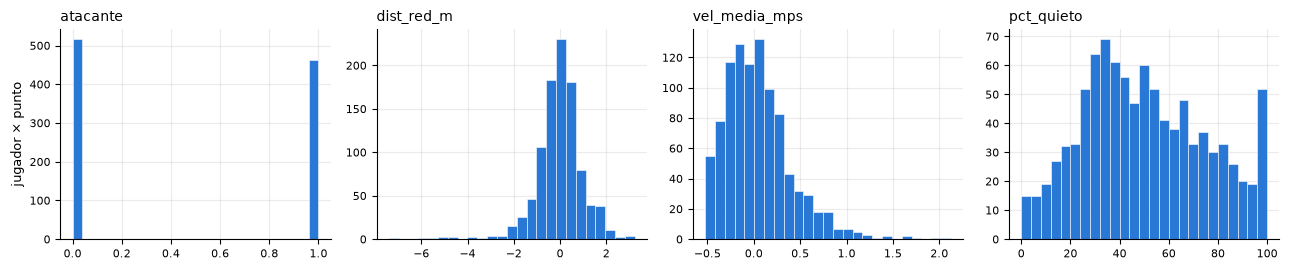

Guardado: data\interim\participaciones.csv


In [11]:
var_video = var.variables_video(video_limpio)
participaciones = (participaciones.merge(var_video.drop(columns='fondo'), on=var.LLAVE_JP, how='left')
                   .merge(var.variables_formulario(jugadores), on='codigo', how='left'))
print('Medidas respecto de su fondo (D22), mismos jugadores en TOP y en BOTTOM:')
display(var.efecto_fondo(participaciones, var.VARIABLES_VIDEO))

for grupo, variables in var.GRUPOS.items():
    print(f'Grupo «{grupo}» (jugador × punto):')
    display(participaciones[var.columnas_jugador(variables)].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

fig, ejes = plt.subplots(1, 4, figsize=(13, 2.8))
for eje, v in zip(ejes, var.VARIABLES_VIDEO):
    eje.hist(participaciones[v].dropna(), bins=25, edgecolor='white', linewidth=0.4)
    eje.set_title(v)
ejes[0].set_ylabel('jugador × punto')
fig.tight_layout()
plt.show()

print('Guardado:', datos.guardar_tabla(participaciones, 'participaciones').relative_to(RAIZ))

**Resultados**
- **Sin corregir, las variables cambian según el fondo.** Se miraron los 18 jugadores que jugaron en los dos fondos (20 para la raqueta). Cuando juegan en TOP salen 1,25 m más cerca de la red (17 de 18), salen atacantes en más puntos (+0,68; 16 de 18), la raqueta sobre el hombro baja (19 de 20) y el giro de la raqueta sube 122 °/s (14 de 20). Como el equipo 1 siempre está en BOTTOM, sin corregir el fondo se confunde con el equipo.
- **Giro de la raqueta:** su valor alto (percentil 90) es 1.127 °/s cuando la raqueta se ve corta en la imagen (≤ 23 px) y 314 °/s cuando se ve larga (> 72 px). O sea, depende de cómo sale la raqueta en la imagen.
- **Comparando con su mismo fondo (D22):** la diferencia de distancia a la red baja de −1,25 a −0,13 m (8 de 18 quedan más altos en TOP) y la de atacante, de +0,68 a +0,26 (11 de 18). Velocidad y % quieto casi no cambian (+0,11 m/s y −6,4 puntos), pero ya antes no iban siempre para el mismo lado: 13 y 7 de 18.
- **Tabla:** `participaciones` tiene 1.132 filas jugador × punto con las 14 variables (18 columnas, porque 3 van en one-hot). Las del formulario están completas; las de video están en 979 (faltan los jugadores sin track, los tracks de menos de 2 s y el partido 17). El 47 % son atacantes y la mediana de % quieto es 48 %.
- Se guardó en `data/interim/participaciones.csv`.

### 1.4 Correlación entre variables

**Objetivo:** revisar que dos variables no digan lo mismo.

**Decisión (D24):** si dos variables tienen una correlación de Spearman de 0,8 o más (positiva o negativa), se deja solo una: la que está entre las 4 que entran primero al modelo (`nivel_padel`, `atacante`, `vel_media_mps` y `estatura_cm`, el modelo 1 de D31). Se usa Spearman porque varias variables son 0/1 o escalas cortas. Las columnas del one-hot de una misma variable no se comparan entre sí.

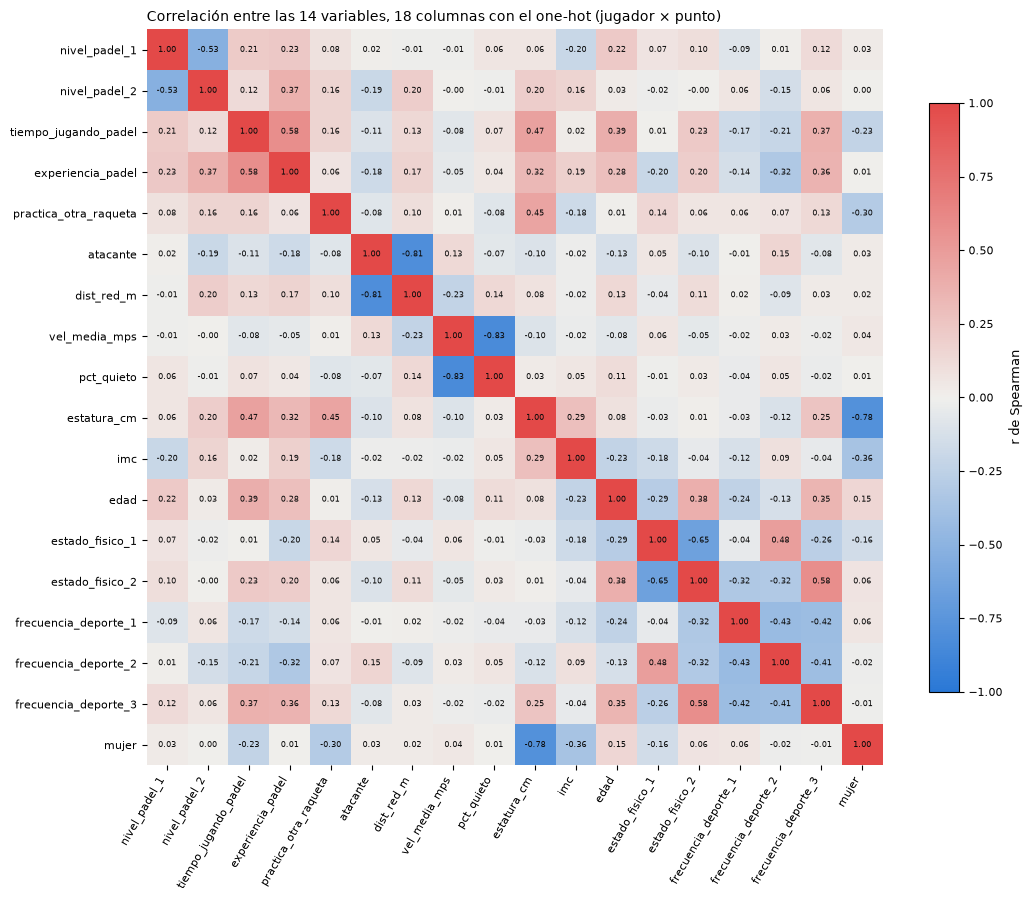

,,r de Spearman
vel_media_mps,pct_quieto,-0.83
atacante,dist_red_m,-0.81


Quedan 12 variables: ['nivel_padel', 'tiempo_jugando_padel', 'experiencia_padel', 'practica_otra_raqueta', 'atacante', 'vel_media_mps', 'estatura_cm', 'imc', 'edad', 'estado_fisico', 'frecuencia_deporte', 'mujer']


In [12]:
corr = participaciones[var.columnas_jugador(var.VARIABLES_JUGADOR)].corr(method='spearman')
divergente = LinearSegmentedColormap.from_list('azul_gris_rojo', ['#2a78d6', '#f0efec', '#e34948'])
fig, eje = plt.subplots(figsize=(11, 9))
im = eje.imshow(corr, cmap=divergente, vmin=-1, vmax=1)
eje.set_xticks(range(len(corr)), corr.columns, rotation=60, ha='right')
eje.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        eje.text(j, i, f'{corr.iat[i, j]:.2f}', ha='center', va='center', fontsize=6, color='#0b0b0b')
eje.grid(False)
eje.spines[:].set_visible(False)
fig.colorbar(im, ax=eje, shrink=0.8, label='r de Spearman')
eje.set_title('Correlación entre las 14 variables, 18 columnas con el one-hot (jugador × punto)')
fig.tight_layout()
plt.show()

pares = var.pares_correlacionados(corr)
display(pares.round(2))
variables_modelo = [v for v in var.VARIABLES_JUGADOR if v not in var.quitar_repetidas(pares)]
print(f'Quedan {len(variables_modelo)} variables:', variables_modelo)

**Resultados**
- Dos pares pasan el límite: `vel_media_mps` con `pct_quieto` (−0,83) y `atacante` con `dist_red_m` (−0,81). Se quitan `pct_quieto` y `dist_red_m`, y quedan **12 variables**.
- Las columnas del one-hot de una misma variable se parecen entre sí (por ejemplo, `estado_fisico_1` con `estado_fisico_2`, −0,65), pero no se comparan porque son la misma variable.
- Entre variables distintas, los siguientes pares más altos no llegan a 0,8: estatura y mujer (−0,78), tiempo jugando y experiencia (0,58), y `estado_fisico_2` con `frecuencia_deporte_3` (0,58).
- Del tipo de juego quedan `atacante` y `vel_media_mps`, que ya están en el modelo 1.

### 1.5 Base unificada para el modelo

**Objetivo:** dejar lista la tabla equipo × punto que entra a la fase 2.

**Decisiones**
- **D25:** solo entran los puntos con los 4 jugadores identificados.
- **D26:** se quitan los puntos en los que a algún jugador le faltan las variables de video; no se imputa nada del video.
- **D27:** cada variable del equipo es el promedio de sus dos jugadores (en las de 0/1, incluidas las del one-hot, queda la proporción: `atacante` = 0,5 quiere decir que uno de los dos es atacante y `nivel_padel_2` = 0,5 que uno de los dos es intermedio o avanzado). Cada punto tiene dos filas, una por equipo, con las variables del equipo (`propio_`) y las del rival (`rival_`). La columna `gano` es 1 si ganó el equipo de esa fila. Las dos filas son una el espejo de la otra, así que da igual cuál es el «equipo 1».

In [13]:
tabla_modelo = var.tabla_equipos(participaciones, puntos, variables_modelo)

completos = puntos.loc[puntos['equipos_completos'], ['partido', 'punto']]
en_tabla = tabla_modelo[['partido', 'punto']].drop_duplicates()
eliminados = completos.merge(en_tabla, how='left', indicator=True).query("_merge == 'left_only'")
print(f'Puntos con los 4 jugadores: {len(completos)} | en la tabla: {len(en_tabla)} | eliminados (D26): {len(eliminados)}',
      eliminados['partido'].value_counts().sort_index().to_dict())
display(datos.resumen_tabla(tabla_modelo, 'tabla_modelo (equipo × punto)'))
print(f"Partidos: {en_tabla['partido'].nunique()} | gana el equipo de la fila: {tabla_modelo['gano'].mean():.0%}")
assert (tabla_modelo.groupby(['partido', 'punto'])['gano'].sum() == 1).all()   # un ganador por punto
print('Ejemplo: las dos filas del primer punto son espejo (variables del modelo 1)')
display(tabla_modelo.head(2)[['partido', 'punto', 'equipo', 'gano', *var.columnas(var.MODELO_1)]].round(2))

print('Guardado:', datos.guardar_tabla(tabla_modelo, 'tabla_modelo', carpeta=datos.DATA_PROCESSED).relative_to(RAIZ))

Puntos con los 4 jugadores: 244 | en la tabla: 224 | eliminados (D26): 20 {10: 4, 14: 1, 17: 9, 23: 1, 27: 4, 35: 1}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,tabla_modelo (equipo × punto),448,36,0,0.0


Partidos: 24 | gana el equipo de la fila: 50%
Ejemplo: las dos filas del primer punto son espejo (variables del modelo 1)


,partido,punto,equipo,gano,propio_nivel_padel_1,rival_nivel_padel_1,propio_nivel_padel_2,rival_nivel_padel_2,propio_atacante,rival_atacante,propio_vel_media_mps,rival_vel_media_mps,propio_estatura_cm,rival_estatura_cm
0,1,1,1,1,1.0,0.5,0.0,0.5,1.0,0.0,-0.00,0.67,178.0,158.5
1,1,1,2,0,0.5,1.0,0.5,0.0,0.0,1.0,0.67,-0.00,158.5,178.0


Guardado: data\processed\tabla_modelo.csv


In [14]:
tabla_modelo.head(5)

,partido,punto,equipo,gano,propio_nivel_padel_1,propio_nivel_padel_2,propio_tiempo_jugando_padel,propio_experiencia_padel,propio_practica_otra_raqueta,propio_atacante,propio_vel_media_mps,propio_estatura_cm,propio_imc,propio_edad,propio_estado_fisico_1,propio_estado_fisico_2,propio_frecuencia_deporte_1,propio_frecuencia_deporte_2,propio_frecuencia_deporte_3,propio_mujer,rival_nivel_padel_1,rival_nivel_padel_2,rival_tiempo_jugando_padel,rival_experiencia_padel,rival_practica_otra_raqueta,rival_atacante,rival_vel_media_mps,rival_estatura_cm,rival_imc,rival_edad,rival_estado_fisico_1,rival_estado_fisico_2,rival_frecuencia_deporte_1,rival_frecuencia_deporte_2,rival_frecuencia_deporte_3,rival_mujer
0,1,1,1,1,1.0,0.0,0.0,0.5,0.5,1.0,-0.000839,178.0,25.550,19.5,0.5,0.0,0.0,0.5,0.0,0.0,0.5,0.5,0.5,1.0,0.5,0.0,0.666726,158.5,22.675,21.5,1.0,0.0,0.0,0.5,0.0,1.0
1,1,1,2,0,0.5,0.5,0.5,1.0,0.5,0.0,0.666726,158.5,22.675,21.5,1.0,0.0,0.0,0.5,0.0,1.0,1.0,0.0,0.0,0.5,0.5,1.0,-0.000839,178.0,25.550,19.5,0.5,0.0,0.0,0.5,0.0,0.0
2,1,2,1,0,1.0,0.0,0.0,0.5,0.5,0.0,-0.103479,178.0,25.550,19.5,0.5,0.0,0.0,0.5,0.0,0.0,0.5,0.5,0.5,1.0,0.5,0.0,0.221412,158.5,22.675,21.5,1.0,0.0,0.0,0.5,0.0,1.0
3,1,2,2,1,0.5,0.5,0.5,1.0,0.5,0.0,0.221412,158.5,22.675,21.5,1.0,0.0,0.0,0.5,0.0,1.0,1.0,0.0,0.0,0.5,0.5,0.0,-0.103479,178.0,25.550,19.5,0.5,0.0,0.0,0.5,0.0,0.0
4,1,3,1,0,1.0,0.0,0.0,0.5,0.5,0.0,0.154691,178.0,25.550,19.5,0.5,0.0,0.0,0.5,0.0,0.0,0.5,0.5,0.5,1.0,0.5,0.0,0.733739,158.5,22.675,21.5,1.0,0.0,0.0,0.5,0.0,1.0


**Resultados**
- `tabla_modelo` tiene 224 puntos de 24 partidos: 448 filas y 36 columnas (`partido`, `punto`, `equipo`, `gano` y las 12 variables, que son 16 columnas con el one-hot, cada una con `propio_` y `rival_`), sin datos faltantes.
- El equipo de la fila gana el 50 % de las veces, porque cada punto tiene un ganador y un perdedor. Las dos filas de cada punto son espejo.
- Se quitaron 20 de los 244 puntos (D26): 9 del partido 17 y 11 de los partidos 10 (4), 27 (4), 14, 23 y 35 (1 cada uno).
- Se guardó en `data/processed/tabla_modelo.csv`.

## Fase 2 — Modelos predictivos

**Objetivo:** predecir qué equipo gana el punto (`gano`) con las 12 variables de la 1.5.

**Decisión (D28):** la fase se divide en 4 partes con todos los temas del curso:
- **2.1:** separar train y test, y definir cómo se evalúan los modelos.
- **2.2:** naive y regresión logística por pasos.
- **2.3:** LASSO/Ridge, árbol, Random Forest, SVM, bagging, boosting y red neuronal.
- **2.4:** ensamblaje y comparación final en test.

### 2.1 Partición y evaluación común

**Objetivo:** apartar unos partidos para el test, que se usan una sola vez al final, y definir cómo se evalúan todos los modelos con el train.

**Decisiones**
- **D29 (test):** 80 % train y 20 % test, separando por partido: los puntos de un partido nunca quedan repartidos entre train y test.
  - Se ordenan los partidos por número (orden del torneo) y se toma 1 de cada 5. Así el test tiene partidos del inicio, de la mitad y del final.
  - Hay 5 formas de hacerlo, según con cuál se empiece. Se escoge la que tiene cerca del 20 % de los partidos, entre el 18 % y el 25 % de los puntos, y en la que el equipo 1 gana casi lo mismo que en el train (±5 puntos). Si quedan varias, la que tiene una proporción de partidos de la cancha 2 más parecida al total.
- **D30 (cómo se evalúa):**
  - **Validación:** se deja un partido por fuera cada vez (19 vueltas), así cada punto se predice con un modelo que no vio su partido. Es como `cross_val_score` del profesor, pero por partido.
  - **Las dos filas de un punto deben sumar 1:** la probabilidad de que gane A es el promedio entre p(A le gana a B) y 1 − p(B le gana a A).
  - **Métrica principal: AUC** (`roc_auc_score`, como en los notebooks del profesor): mide qué tan bien el modelo pone a los ganadores por encima de los perdedores. Vale 0,5 si es como lanzar una moneda y 1 si ordena todo bien. Al lado van la accuracy y el F1, también como el profesor.
  - **Intervalos del 95 %:** se sacan con bootstrap por partido sobre las predicciones (1.000 muestras, semilla 2026). Todos los modelos usan las mismas muestras.

In [15]:
partidos_modelo = puntos[puntos['partido'].isin(tabla_modelo['partido'])].drop_duplicates('partido')
pct_cancha_2 = 100 * (partidos_modelo['cancha'] == 2).mean()
print(f'Partidos de la cancha 2: {pct_cancha_2:.1f} % de {len(partidos_modelo)}')
opciones = mod.opciones_test(tabla_modelo, puntos)
display(opciones)

partidos_test = mod.elegir_test(opciones, pct_cancha_2)
train = tabla_modelo[~tabla_modelo['partido'].isin(partidos_test)].reset_index(drop=True)
test = tabla_modelo[tabla_modelo['partido'].isin(partidos_test)].reset_index(drop=True)
print('Partidos de test (D29):', [int(p) for p in partidos_test])
display(pd.DataFrame({'partidos': [train['partido'].nunique(), test['partido'].nunique()],
                      'puntos': [len(train) // 2, len(test) // 2], 'filas': [len(train), len(test)]}, index=['train', 'test']))

jugadores_de = lambda t: set(participaciones.merge(t[['partido', 'punto']].drop_duplicates())['codigo'])
solo_test = jugadores_de(test) - jugadores_de(train)
print('Jugadores del test que no juegan en el train:', jugadores.loc[jugadores['codigo'].isin(solo_test), 'nombre'].tolist())

muestras = mod.remuestreos(train['partido'].unique())
print(f'Validación: {train["partido"].nunique()} pliegues (uno por partido) | intervalos: {len(muestras)} remuestreos de partidos (D30)')

Partidos de la cancha 2: 37.5 % de 24


,test,partidos,pct_puntos,pct_cancha_2,fps,gana_e1_test,gana_e1_train,dif_estandarizada_media
arranque,,,,,,,,
1,"[1, 10, 18, 26, 32]",5,22.3,80,"[22, 60]",42,43,0.26
2,"[3, 11, 20, 27, 35]",5,16.5,20,"[30, 60]",41,43,0.29
3,"[5, 13, 23, 28, 37]",5,17.4,20,"[24, 30, 60]",31,45,0.34
4,"[7, 14, 24, 29, 39]",5,23.7,40,"[24, 60]",43,42,0.20
5,"[9, 16, 25, 31]",4,20.1,25,"[30, 60]",53,40,0.16


Partidos de test (D29): [7, 14, 24, 29, 39]


,partidos,puntos,filas
train,19,171,342
test,5,53,106


Jugadores del test que no juegan en el train: ['Laura Sofía Rodríguez González']
Validación: 19 pliegues (uno por partido) | intervalos: 1000 remuestreos de partidos (D30)


**Resultados**
- **Test (D29):** partidos 7, 14, 24, 29 y 39, con 53 puntos (23,7 %) y 106 filas. El train queda con 19 partidos, 171 puntos y 342 filas.
- **Por qué esa opción:** solo la 1 y la 4 cumplen todo: 5 partidos, entre el 18 % y el 25 % de los puntos, y el equipo 1 gana casi igual que en el train (42 % contra 43 % y 43 % contra 42 %). Se escoge la 4 porque el 40 % de sus partidos son de la cancha 2 (en total es el 37,5 %), mientras que en la 1 es el 80 %. Además tiene una cámara de 24 fps y es de las más parecidas al train en las variables del modelo.
- **Jugadora nueva:** Laura Sofía Rodríguez González solo juega en el test.
- **Evaluación (D30):** 19 vueltas de validación, una por partido, e intervalos con 1.000 muestras de partidos.

### 2.2 Naive y regresión logística por pasos

**Objetivo:** tener la referencia más básica (el naive) y armar la logística de a poco: primero 4 variables y luego un grupo a la vez.

**Decisiones**
- **Naive:** siempre predice la proporción de puntos ganados del train. Como cada punto tiene una fila ganadora y una perdedora, esa proporción es 0,5: su AUC es 0,5 y su accuracy 50 %. Su F1 sale 0,67 solo porque dice «gana» en todas las filas.
- **D31 (por pasos):**
  - Modelo 1: `nivel_padel`, `atacante`, `vel_media_mps` y `estatura_cm`.
  - Luego se agrega el resto de nivel de juego y después el resto de atributos físicos. Del tipo de juego no queda nada por agregar (D24).
  - Un grupo se queda solo si mejora el AUC de forma clara: el intervalo del 95 % de la mejora tiene que quedar por encima de 0. Si no, se prueban sus variables una por una con la misma regla. Así el modelo se mantiene simple (parsimonia).
  - Se usa la logística de `scikit-learn`, como en el notebook del profesor, con las variables en la misma escala (`StandardScaler`) dentro de cada vuelta.
  - En la tabla, `dif_vs_actual` es cuánto cambia el AUC frente al modelo que va quedando (positivo = mejora), con su intervalo del 95 %.

,paso,agrega,auc,dif_vs_actual,dif_IC95,se_queda
0,modelo 1,"nivel_padel, atacante, vel_media_mps, estatura_cm",0.6093,NaN,,True
1,+ nivel de juego,"tiempo_jugando_padel, experiencia_padel, pract...",0.5796,-0.0298,[-0.071; 0.011],False
2,+ tiempo_jugando_padel,tiempo_jugando_padel,0.5954,-0.0139,[-0.039; 0.012],False
3,+ experiencia_padel,experiencia_padel,0.6027,-0.0066,[-0.046; 0.028],False
4,+ practica_otra_raqueta,practica_otra_raqueta,0.5969,-0.0124,[-0.030; 0.001],False
5,+ atributos físicos,"imc, edad, estado_fisico, frecuencia_deporte, ...",0.5777,-0.0316,[-0.080; 0.008],False
6,+ imc,imc,0.6078,-0.0015,[-0.019; 0.013],False
7,+ edad,edad,0.6118,0.0025,[-0.028; 0.025],False
8,+ estado_fisico,estado_fisico,0.6156,0.0063,[-0.030; 0.040],False
9,+ frecuencia_deporte,frecuencia_deporte,0.5545,-0.0549,[-0.114; -0.012],False


,auc,auc_IC95,accuracy,accuracy_IC95,f1,f1_IC95
naive,0.5,[0.500; 0.500],0.5,[0.500; 0.500],0.667,[0.667; 0.667]
modelo 1,0.609,[0.526; 0.711],0.591,[0.508; 0.683],0.591,[0.508; 0.683]
+ nivel de juego,0.58,[0.491; 0.686],0.567,[0.483; 0.658],0.567,[0.483; 0.658]
+ tiempo_jugando_padel,0.595,[0.512; 0.703],0.585,[0.511; 0.673],0.585,[0.511; 0.673]
+ experiencia_padel,0.603,[0.510; 0.710],0.585,[0.500; 0.677],0.585,[0.500; 0.677]
+ practica_otra_raqueta,0.597,[0.518; 0.697],0.591,[0.511; 0.679],0.591,[0.511; 0.679]
+ atributos físicos,0.578,[0.496; 0.680],0.573,[0.500; 0.656],0.573,[0.500; 0.656]
+ imc,0.608,[0.528; 0.705],0.585,[0.511; 0.667],0.585,[0.511; 0.667]
+ edad,0.612,[0.527; 0.711],0.596,[0.517; 0.683],0.596,[0.517; 0.683]
+ estado_fisico,0.616,[0.529; 0.722],0.561,[0.473; 0.661],0.561,[0.473; 0.661]


Variables de la logística final: ['nivel_padel', 'atacante', 'vel_media_mps', 'estatura_cm']


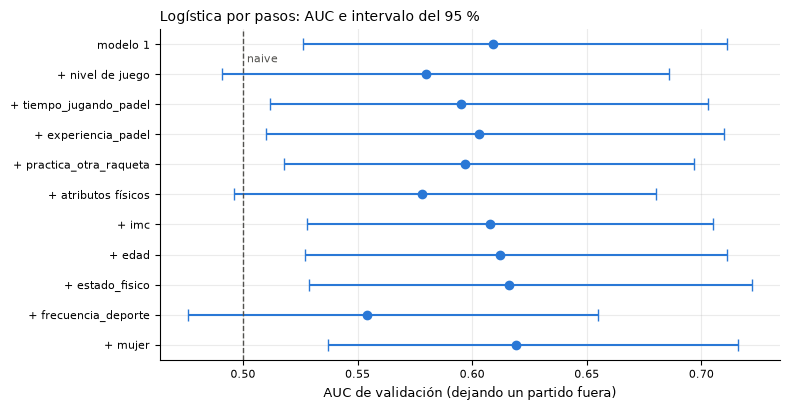

In [16]:
naive = DummyClassifier(strategy='prior')
logistica = make_pipeline(StandardScaler(), LogisticRegression())
grupos = {g: [v for v in vs if v in variables_modelo] for g, vs in var.GRUPOS.items()}

pred_naive = mod.predecir(naive, train, var.columnas(var.MODELO_1))
variables_logistica, pasos, pred_pasos, pred_logistica = mod.seleccion_por_pasos(logistica, train, var.MODELO_1, grupos, muestras)
display(pasos)
tabla_pasos = mod.resumen(train, {'naive': pred_naive, **pred_pasos}, muestras)
display(tabla_pasos)
print('Variables de la logística final:', variables_logistica)

nombres = list(pred_pasos)
auc = tabla_pasos.loc[nombres, 'auc'].astype(float).to_numpy()
ic = np.array([[float(x) for x in s.strip('[]').split(';')] for s in tabla_pasos.loc[nombres, 'auc_IC95']])
fig, eje = plt.subplots(figsize=(8, 4.2))
eje.errorbar(auc, range(len(nombres)), xerr=[auc - ic[:, 0], ic[:, 1] - auc], fmt='o', capsize=4)
eje.axvline(0.5, color='#52514e', linestyle='--', linewidth=1)
eje.text(0.5, 0.5, ' naive', color='#52514e', fontsize=8, va='center')
eje.set_yticks(range(len(nombres)), nombres)
eje.invert_yaxis()
eje.set_xlabel('AUC de validación (dejando un partido fuera)')
eje.set_title('Logística por pasos: AUC e intervalo del 95 %')
fig.tight_layout()
plt.show()

In [17]:
# Coeficientes de la logística final con todo el train (variables estandarizadas) e intervalo bootstrap
display(mod.coeficientes(logistica, train, var.columnas(variables_logistica), muestras))

,coeficiente,odds_ratio,IC95_inf,IC95_sup
propio_nivel_padel_1,0.244,1.276,-0.049,0.591
rival_nivel_padel_1,-0.244,0.784,-0.591,0.049
propio_nivel_padel_2,0.195,1.215,-0.127,0.487
rival_nivel_padel_2,-0.195,0.823,-0.487,0.127
propio_atacante,-0.081,0.923,-0.275,0.141
rival_atacante,0.081,1.084,-0.141,0.275
propio_vel_media_mps,-0.212,0.809,-0.659,0.120
rival_vel_media_mps,0.212,1.236,-0.120,0.659
propio_estatura_cm,0.177,1.193,-0.043,0.539
rival_estatura_cm,-0.177,0.838,-0.539,0.043


**Resultados**
- **Naive:** AUC 0,5 y accuracy 50 % (su F1 de 0,67 sale de decir «gana» en todas las filas).
- **Modelo 1:** AUC 0,609 [0,526; 0,711] y accuracy 59 % [51 %; 68 %]. Ordena los puntos mejor que el azar, porque el intervalo del AUC no incluye 0,5.
- **Grupos:** ninguno mejora de forma clara (nivel de juego −0,030 y atributos físicos −0,032). Una por una tampoco entra ninguna: la que más sube es `mujer` (+0,010), pero su intervalo [−0,027; 0,045] incluye el 0; `frecuencia_deporte` lo baja de forma clara (−0,055). Por la regla (D31), la logística final es el modelo 1: 4 variables, que son 5 columnas por equipo con el one-hot del nivel.
- **Coeficientes del modelo 1:** ninguno tiene un intervalo que deje por fuera el 0. Los que más se acercan son `nivel_padel_1` (ser principiante frente a jugar por primera vez: +0,24; intervalo [−0,05; 0,59]) y `estatura_cm` (+0,18; [−0,04; 0,54]). Los coeficientes `propio_` y `rival_` son iguales con signo contrario porque las dos filas de cada punto son espejo.

### 2.3 Otros modelos del curso

**Objetivo:** probar los demás modelos del curso con la misma evaluación de la 2.1 y la misma regla de parsimonia de la 2.2.

**Decisiones**
- **D32 (pasos por modelo):** cada modelo repite la selección por pasos de la 2.2. Empieza con las 4 variables del modelo 1 y solo agrega un grupo o una variable si el AUC mejora de forma clara (D31). Así cada modelo termina con sus propias variables, escogidas entre las 12.
- **D33 (hiperparámetros):** se buscan una vez por modelo, con las 4 variables del modelo 1, usando búsqueda bayesiana (`BayesSearchCV`) como en el notebook 05 del profesor: 40 evaluaciones por modelo y AUC como métrica. Los pliegues son por partido (se deja un partido por fuera cada vez). Lo que se busca en cada modelo:
  - LASSO y Ridge: `C` entre 0,0001 y 10, que dice cuánto se castigan los coeficientes.
  - Árbol: profundidad de 1 a 10 y mínimo de 5 a 60 filas por hoja.
  - Random Forest: de 25 a 500 árboles, profundidad de 1 a 10 y mínimo de 5 a 60 filas por hoja.
  - SVM: kernel lineal o rbf, `C` entre 0,0001 y 10 y `gamma` entre 0,001 y 1.
  - Bagging: profundidad de 1 a 10 y mínimo de 5 a 60 filas por hoja en cada árbol, y tamaño de cada muestra entre el 30 % y el 100 % del train.
  - AdaBoost, Gradient Boosting y XGBoost: de 25 a 500 árboles, tasa de aprendizaje entre 0,001 y 1 y profundidad de 1 a 10 (AdaBoost usa árboles de profundidad 1).
  - Red neuronal: una capa de 4 a 64 neuronas, activación relu o sigmoide y castigo `alpha` entre 0,001 y 10.
  - Ojo: escoger y reportar con los mismos pliegues da un AUC un poco optimista; el test de la 2.4 no tiene ese sesgo.
- **D34 (SVM):** sus probabilidades salen de `SVC(probability=True)`, como en el notebook del profesor. Para calcularlas, `scikit-learn` hace una validación interna que mezcla puntos de un mismo partido.
- **D35 (red neuronal):** se usa `MLPClassifier` de `scikit-learn`, con la misma idea del notebook 08 del profesor: una capa densa (la búsqueda bayesiana no acepta listas de capas), activación relu o sigmoide, optimizador adam y lotes de 128. El profesor usa Keras/TensorFlow, pero TensorFlow no tiene versión estable para Python 3.14. No se usa la parada temprana (el profesor tampoco la usa) porque separaría una validación al azar que mezcla puntos de un mismo partido.

In [18]:
C = Real(1e-4, 10, prior='log-uniform')
arboles, tasa = Integer(25, 500), Real(1e-3, 1, prior='log-uniform')
profundidad, hoja = Integer(1, 10), Integer(5, 60)
modelos = {
    'LASSO': (make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver='liblinear')),
              {'logisticregression__C': C}),
    'Ridge': (make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=0, solver='liblinear')),
              {'logisticregression__C': C}),
    'Árbol': (DecisionTreeClassifier(random_state=datos.SEMILLA),
              {'max_depth': profundidad, 'min_samples_leaf': hoja}),
    'Random Forest': (RandomForestClassifier(random_state=datos.SEMILLA),
                      {'n_estimators': arboles, 'max_depth': profundidad, 'min_samples_leaf': hoja}),
    'SVM': (make_pipeline(StandardScaler(), SVC(probability=True, random_state=datos.SEMILLA)),
            {'svc__kernel': Categorical(['linear', 'rbf']), 'svc__C': C, 'svc__gamma': Real(1e-3, 1, prior='log-uniform')}),
    'Bagging': (BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=datos.SEMILLA),
                {'estimator__max_depth': profundidad, 'estimator__min_samples_leaf': hoja, 'max_samples': Real(0.3, 1.0)}),
    'AdaBoost': (AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=datos.SEMILLA),
                 {'n_estimators': arboles, 'learning_rate': tasa}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=datos.SEMILLA),
                          {'n_estimators': arboles, 'learning_rate': tasa, 'max_depth': profundidad}),
    'XGBoost': (XGBClassifier(random_state=datos.SEMILLA, n_jobs=1),
                {'n_estimators': arboles, 'learning_rate': tasa, 'max_depth': profundidad}),
    'Red neuronal': (make_pipeline(StandardScaler(), MLPClassifier(batch_size=128, max_iter=1000, random_state=datos.SEMILLA)),
                     {'mlpclassifier__hidden_layer_sizes': Integer(4, 64), 'mlpclassifier__activation': Categorical(['relu', 'logistic']),
                      'mlpclassifier__alpha': Real(1e-3, 10, prior='log-uniform')}),
}

# SVC(probability=True) como en el notebook del profesor (D34); en scikit-learn 1.9 avisa que se quitará en la 1.11
warnings.filterwarnings('ignore', message='The `probability` parameter was deprecated')
warnings.filterwarnings('ignore', message='The objective has been evaluated at point')   # aviso de scikit-optimize
ajustes = {}
for nombre, (modelo, espacio) in modelos.items():
    t0 = time.time()
    ajustes[nombre] = mod.ajustar(modelo, espacio, train, var.MODELO_1, grupos, muestras)
    a = ajustes[nombre]
    print(f"{nombre} ({time.time() - t0:.0f} s): {a['hiperparametros']}")

LASSO (67 s): {'logisticregression__C': 0.19170087126014457}


Ridge (66 s): {'logisticregression__C': 0.04026888684299206}


Árbol (90 s): {'max_depth': 9, 'min_samples_leaf': 46}


Random Forest (175 s): {'max_depth': 4, 'min_samples_leaf': 60, 'n_estimators': 187}


SVM (85 s): {'svc__C': 0.03242060517306404, 'svc__gamma': 0.005263065560377743, 'svc__kernel': 'linear'}


Bagging (127 s): {'estimator__max_depth': 2, 'estimator__min_samples_leaf': 58, 'max_samples': 0.6068620190495012}


AdaBoost (179 s): {'learning_rate': 0.001057159723351303, 'n_estimators': 179}


Gradient Boosting (185 s): {'learning_rate': 0.001, 'max_depth': 1, 'n_estimators': 399}


XGBoost (217 s): {'learning_rate': 0.008869617795473742, 'max_depth': 1, 'n_estimators': 25}


Red neuronal (131 s): {'mlpclassifier__activation': 'logistic', 'mlpclassifier__alpha': 0.7799553376277303, 'mlpclassifier__hidden_layer_sizes': 11}


In [19]:
# Pasos de cada modelo: cuánto cambia el AUC con cada grupo o variable (✓ = se queda)
pasos_2_3 = pd.concat({n: a['pasos'].set_index('paso') for n, a in ajustes.items()}, names=['modelo'])
marca = pasos_2_3['dif_vs_actual'].round(3).astype(str) + np.where(pasos_2_3['se_queda'], ' ✓', '')
display(marca.unstack('paso').reindex(columns=pasos_2_3.index.get_level_values('paso').unique()).drop(columns='modelo 1').fillna(''))
display(pd.DataFrame({'variables': {n: ', '.join(a['variables']) for n, a in ajustes.items()}}))

paso,+ nivel de juego,+ tiempo_jugando_padel,+ experiencia_padel,+ practica_otra_raqueta,+ atributos físicos,+ imc,+ edad,+ estado_fisico,+ frecuencia_deporte,+ mujer
modelo,,,,,,,,,,
LASSO,-0.032,-0.025,-0.018,0.0,-0.002,-0.004,-0.008,-0.001,-0.012,0.028 ✓
Ridge,-0.018,-0.01,-0.0,-0.007,-0.007,0.002,0.003,0.006,-0.035,0.013
Árbol,-0.03,-0.036,0.004,-0.0,-0.047,-0.009,-0.028,-0.002,-0.013,-0.003
Random Forest,-0.003,-0.005,-0.006,-0.005,-0.008,-0.017,-0.002,-0.014,-0.015,0.001
SVM,-0.048,-0.03,-0.033,-0.004,-0.033,0.004,-0.016,-0.017,-0.015,0.005
Bagging,-0.014,-0.014,-0.0,-0.0,-0.014,-0.012,-0.004,-0.005,-0.006,0.0
AdaBoost,-0.003,0.01,0.023,0.004,-0.002,-0.014,0.01,0.015,0.009,0.016
Gradient Boosting,-0.0,0.0,-0.0,0.0,-0.006,-0.007,-0.0,-0.0,0.0,0.0
XGBoost,0.0,0.0,0.0,0.0,-0.008,-0.011,0.0,0.0,0.0,0.003


,variables
LASSO,"nivel_padel, atacante, vel_media_mps, estatura..."
Ridge,"nivel_padel, atacante, vel_media_mps, estatura_cm"
Árbol,"nivel_padel, atacante, vel_media_mps, estatura_cm"
Random Forest,"nivel_padel, atacante, vel_media_mps, estatura_cm"
SVM,"nivel_padel, atacante, vel_media_mps, estatura_cm"
Bagging,"nivel_padel, atacante, vel_media_mps, estatura_cm"
AdaBoost,"nivel_padel, atacante, vel_media_mps, estatura_cm"
Gradient Boosting,"nivel_padel, atacante, vel_media_mps, estatura_cm"
XGBoost,"nivel_padel, atacante, vel_media_mps, estatura_cm"
Red neuronal,"nivel_padel, atacante, vel_media_mps, estatura_cm"


,auc,auc_IC95,accuracy,accuracy_IC95,f1,f1_IC95
Red neuronal,0.632,[0.550; 0.721],0.614,[0.542; 0.691],0.614,[0.542; 0.691]
Random Forest,0.629,[0.556; 0.716],0.605,[0.530; 0.686],0.606,[0.530; 0.687]
SVM,0.626,[0.548; 0.720],0.62,[0.564; 0.688],0.624,[0.570; 0.691]
Bagging,0.621,[0.541; 0.720],0.658,[0.593; 0.735],0.661,[0.595; 0.737]
Ridge,0.62,[0.540; 0.716],0.596,[0.511; 0.686],0.596,[0.511; 0.686]
LASSO,0.615,[0.541; 0.708],0.602,[0.527; 0.680],0.602,[0.527; 0.680]
Logística (2.2),0.609,[0.526; 0.711],0.591,[0.508; 0.683],0.591,[0.508; 0.683]
AdaBoost,0.604,[0.527; 0.689],0.579,[0.523; 0.647],0.609,[0.521; 0.682]
Árbol,0.586,[0.514; 0.674],0.596,[0.543; 0.666],0.603,[0.528; 0.682]
Gradient Boosting,0.579,[0.513; 0.663],0.579,[0.523; 0.647],0.636,[0.578; 0.693]


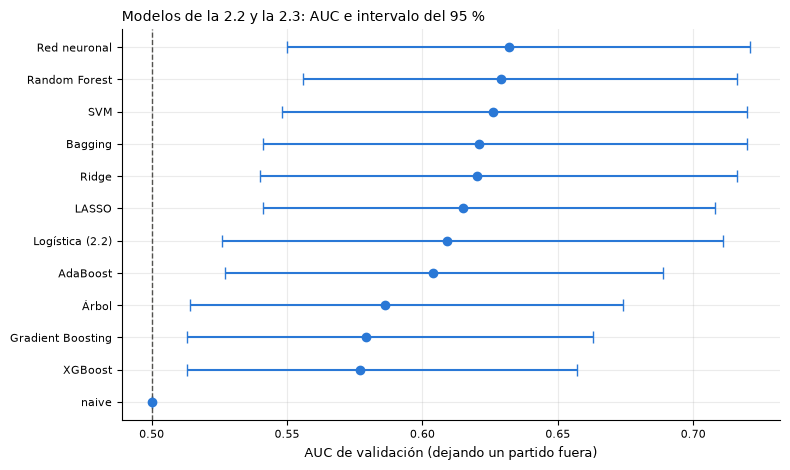

In [20]:
# Comparación de todos los modelos en validación (AUC, accuracy y F1 con intervalo del 95 %)
predicciones = {'naive': pred_naive, 'Logística (2.2)': pred_logistica, **{n: a['prediccion'] for n, a in ajustes.items()}}
comparacion = mod.resumen(train, predicciones, muestras).sort_values('auc', ascending=False)
display(comparacion)

auc = comparacion['auc'].astype(float).to_numpy()
ic = np.array([[float(x) for x in s.strip('[]').split(';')] for s in comparacion['auc_IC95']])
fig, eje = plt.subplots(figsize=(8, 4.8))
eje.errorbar(auc, range(len(auc)), xerr=[auc - ic[:, 0], ic[:, 1] - auc], fmt='o', capsize=4)
eje.axvline(0.5, color='#52514e', linestyle='--', linewidth=1)
eje.set_yticks(range(len(auc)), comparacion.index)
eje.invert_yaxis()
eje.set_xlabel('AUC de validación (dejando un partido fuera)')
eje.set_title('Modelos de la 2.2 y la 2.3: AUC e intervalo del 95 %')
fig.tight_layout()
plt.show()

**Resultados**
- **Hiperparámetros escogidos (búsqueda bayesiana):**
  - LASSO: C = 0,19. Ridge: C = 0,04. SVM: kernel lineal con C = 0,03.
  - Árbol: profundidad 9 y mínimo 46 filas por hoja.
  - Random Forest: 187 árboles, profundidad 4 y mínimo 60 filas por hoja.
  - Bagging: árboles de profundidad 2, mínimo 58 filas por hoja y muestras del 61 % del train.
  - AdaBoost: 179 árboles con tasa 0,001. Gradient Boosting: 399 árboles, tasa 0,001 y profundidad 1. XGBoost: 25 árboles, tasa 0,009 y profundidad 1.
  - Red neuronal: una capa de 11 neuronas, activación sigmoide y `alpha` = 0,78.
  - Varios escogieron el extremo más simple de su rango: la tasa mínima (0,001) en AdaBoost y Gradient Boosting, el mínimo de árboles (25) en XGBoost y el máximo de filas por hoja (60) en Random Forest.
- **Pasos:** 9 de los 10 modelos se quedan con las 4 del modelo 1. Solo LASSO agrega `mujer` (+0,028).
- **Comparación (AUC de validación):**
  - Red neuronal 0,632 [0,550; 0,721], Random Forest 0,629, SVM 0,626, Bagging 0,621, Ridge 0,620 y LASSO 0,615; la logística de la 2.2 queda en 0,609.
  - AdaBoost (0,604), Árbol (0,586), Gradient Boosting (0,579) y XGBoost (0,577) quedan por debajo de la logística.
  - Todos ordenan los puntos mejor que el azar (en ninguno el intervalo del AUC incluye 0,5), pero las diferencias entre modelos (de 0,577 a 0,632) son mucho más pequeñas que el ancho de los intervalos.
- **Para la 2.4 (D36):** los 4 mejores por AUC son la red neuronal, Random Forest, SVM y Bagging.

### 2.4 Ensamblaje y comparación final en test

**Objetivo:** combinar los 4 mejores modelos de la 2.3 con un voto ponderado, escoger el modelo para la fase 4 y medir todos los modelos una sola vez en el test.

**Decisiones**
- **D36:** al ensamblaje entran los 4 mejores modelos de la 2.3 por AUC de validación.
- **D37 (voto ponderado):** igual que en la parte 5 del notebook 06 del profesor, cada modelo tiene un peso α = (1 − error) / suma, donde 1 − error es su accuracy de validación de la 2.3 (el profesor usa el error out-of-bag; aquí, el de la validación por partido; los dos son error en datos que el modelo no vio). En vez de sumar votos 0/1 se suman las probabilidades: p(ensamblaje) = Σ α × p(modelo), para tener una probabilidad en la fase 4. Ojo: los pesos y el resultado del ensamblaje en validación salen de las mismas predicciones, así que ese resultado es un poco optimista.
- **D38 (modelo final):** pasa a la fase 4 el de mayor AUC de validación entre el ensamblaje y los 10 modelos de la 2.3. Se escoge antes de mirar el test.
- **D39 (test):** cada modelo se entrena con todo el train (con sus hiperparámetros y sus variables) y se mide una sola vez en los 5 partidos de test, con AUC, accuracy y F1 e intervalo del 95 % por bootstrap de partidos. Con 5 partidos el intervalo sale muy ancho.

In [21]:
# Voto ponderado con los 4 mejores de la 2.3 (D36, D37)
mejores = comparacion.drop(['naive', 'Logística (2.2)']).index[:4].tolist()
pesos = mod.pesos_accuracy(train, predicciones, mejores)
print('Pesos del voto ponderado (α):')
display(pesos.round(3).rename('α').to_frame())

predicciones['Ensamblaje'] = mod.ensamblar(predicciones, pesos)
validacion = mod.resumen(train, predicciones, muestras).sort_values('auc', ascending=False)
display(validacion)

# Modelo para la fase 4: el de mayor AUC de validación, escogido antes de mirar el test (D38)
modelo_final = validacion.drop(['naive', 'Logística (2.2)'])['auc'].astype(float).idxmax()
print('Modelo para la fase 4 (D38):', modelo_final)

Pesos del voto ponderado (α):


,α
Red neuronal,0.246
Random Forest,0.242
SVM,0.248
Bagging,0.263


,auc,auc_IC95,accuracy,accuracy_IC95,f1,f1_IC95
Ensamblaje,0.64,[0.563; 0.734],0.649,[0.587; 0.721],0.649,[0.587; 0.721]
Red neuronal,0.632,[0.550; 0.721],0.614,[0.542; 0.691],0.614,[0.542; 0.691]
Random Forest,0.629,[0.556; 0.716],0.605,[0.530; 0.686],0.606,[0.530; 0.687]
SVM,0.626,[0.548; 0.720],0.62,[0.564; 0.688],0.624,[0.570; 0.691]
Bagging,0.621,[0.541; 0.720],0.658,[0.593; 0.735],0.661,[0.595; 0.737]
Ridge,0.62,[0.540; 0.716],0.596,[0.511; 0.686],0.596,[0.511; 0.686]
LASSO,0.615,[0.541; 0.708],0.602,[0.527; 0.680],0.602,[0.527; 0.680]
Logística (2.2),0.609,[0.526; 0.711],0.591,[0.508; 0.683],0.591,[0.508; 0.683]
AdaBoost,0.604,[0.527; 0.689],0.579,[0.523; 0.647],0.609,[0.521; 0.682]
Árbol,0.586,[0.514; 0.674],0.596,[0.543; 0.666],0.603,[0.528; 0.682]


Modelo para la fase 4 (D38): Ensamblaje


,auc,auc_IC95,accuracy,accuracy_IC95,f1,f1_IC95
LASSO,0.596,[0.448; 0.727],0.547,[0.418; 0.647],0.547,[0.418; 0.647]
Random Forest,0.592,[0.521; 0.686],0.585,[0.529; 0.647],0.585,[0.529; 0.647]
Árbol,0.591,[0.463; 0.735],0.547,[0.482; 0.625],0.586,[0.528; 0.654]
AdaBoost,0.588,[0.518; 0.648],0.566,[0.510; 0.630],0.629,[0.576; 0.677]
Gradient Boosting,0.588,[0.518; 0.648],0.566,[0.510; 0.630],0.629,[0.576; 0.677]
XGBoost,0.588,[0.518; 0.648],0.566,[0.510; 0.630],0.629,[0.576; 0.677]
Ensamblaje,0.581,[0.425; 0.708],0.566,[0.478; 0.647],0.566,[0.478; 0.647]
Logística (2.2),0.578,[0.400; 0.722],0.566,[0.478; 0.647],0.566,[0.478; 0.647]
Ridge,0.571,[0.375; 0.723],0.547,[0.460; 0.627],0.547,[0.460; 0.627]
SVM,0.57,[0.388; 0.710],0.566,[0.478; 0.647],0.566,[0.478; 0.647]


Modelo para la fase 4 (Ensamblaje): AUC 0.64 en validación y 0.581 en test


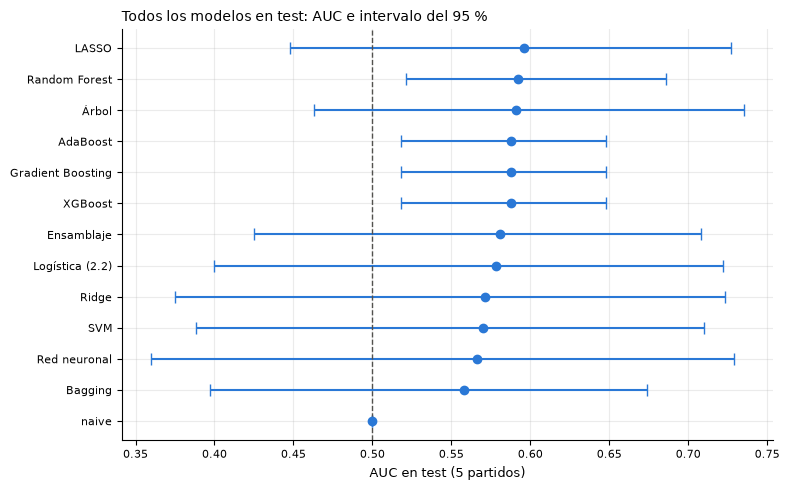

In [22]:
# Test: cada modelo se entrena con todo el train y se mide una sola vez en los 5 partidos de test (D39)
finales = {'naive': (naive, var.MODELO_1), 'Logística (2.2)': (logistica, variables_logistica),
           **{n: (a['modelo'], a['variables']) for n, a in ajustes.items()}}
pred_test = {n: mod.predecir_test(m, train, test, var.columnas(v)) for n, (m, v) in finales.items()}
pred_test['Ensamblaje'] = mod.ensamblar(pred_test, pesos)

muestras_test = mod.remuestreos(test['partido'].unique())
resultado_test = mod.resumen(test, pred_test, muestras_test).sort_values('auc', ascending=False)
display(resultado_test)
print(f"Modelo para la fase 4 ({modelo_final}): AUC {validacion.loc[modelo_final, 'auc']} en validación "
      f"y {resultado_test.loc[modelo_final, 'auc']} en test")

auc = resultado_test['auc'].astype(float).to_numpy()
ic = np.array([[float(x) for x in s.strip('[]').split(';')] for s in resultado_test['auc_IC95']])
fig, eje = plt.subplots(figsize=(8, 5))
eje.errorbar(auc, range(len(auc)), xerr=[auc - ic[:, 0], ic[:, 1] - auc], fmt='o', capsize=4)
eje.axvline(0.5, color='#52514e', linestyle='--', linewidth=1)
eje.set_yticks(range(len(auc)), resultado_test.index)
eje.invert_yaxis()
eje.set_xlabel('AUC en test (5 partidos)')
eje.set_title('Todos los modelos en test: AUC e intervalo del 95 %')
fig.tight_layout()
plt.show()

**Resultados**
- **Pesos (D37):** red neuronal 0,246, Random Forest 0,242, SVM 0,248 y Bagging 0,263. Salen casi iguales porque sus accuracy de validación se parecen.
- **Validación:** el ensamblaje tiene AUC 0,640 [0,563; 0,734] y accuracy 65 %, el AUC más alto de todos.
- **Modelo para la fase 4 (D38):** el ensamblaje.
- **Test (D39):**
  - Todos los modelos tienen AUC mayor que 0,5 en test (de 0,558 a 0,596). El mayor es LASSO (0,596). El ensamblaje queda en 0,581 [0,425; 0,708].
  - Random Forest, AdaBoost, Gradient Boosting y XGBoost son los únicos cuyo intervalo deja por fuera el 0,5. AdaBoost, Gradient Boosting y XGBoost dan exactamente los mismos resultados en test; los tres usan árboles de profundidad 1 con una tasa de aprendizaje muy baja (0,001 a 0,009).
  - El orden de los modelos cambia entre validación y test, y los intervalos se solapan casi por completo: con 5 partidos, el test no alcanza para separar un modelo de otro.

## Fase 3 — Distribuciones

**Objetivo:** encontrar la distribución de cada variable que la fase 4 tiene que sortear para simular puntos entre parejas que no jugaron juntas.

**Decisiones**
- **D40 (qué se sortea):** el ensamblaje que pasa a la fase 4 (D38) usa `nivel_padel`, `atacante`, `vel_media_mps` y `estatura_cm`. El nivel y la estatura son fijos de cada jugador (formulario), así que no se sortean. Solo se busca la distribución de `atacante` y `vel_media_mps`, que cambian de punto a punto. La fase tiene 3 partes:
  - **3.1:** exploración.
  - **3.2:** ajuste con todos los jugadores.
  - **3.3:** ajuste por jugador y tabla para la fase 4.
- **D41 (datos):** se usan todas las filas jugador × punto con variables de video, no solo las de los puntos del modelo (D26): para la distribución de un jugador no hace falta que los otros 3 del punto estén completos.
- **D42 (por jugador):** cada jugador tiene su propia distribución. Si tiene menos de 10 puntos, usa la de todos los jugadores juntos (la global).

### 3.1 Exploración

**Objetivo:** ver cuántos datos tiene cada jugador, qué forma tienen las dos variables, si los jugadores son distintos entre sí y qué relaciones tendría que conservar la fase 4 al sortear.

- **¿Todos los jugadores son iguales?** Chi² para `atacante` (¿todos son atacantes en la misma proporción?) y Kruskal-Wallis para `vel_media_mps` (¿todos tienen la misma distribución?). Si se rechazan, una sola distribución no sirve para todos (D42).
- **Dependencias (Spearman):** entre las dos variables del mismo jugador en el mismo punto, entre compañeros del mismo punto y de cada jugador entre un punto y el anterior suyo. Además, cómo cambian por tercio del torneo (partidos en orden de número, D29).

Filas jugador × punto con video (D41): 979, de 30 jugadores | puntos por jugador: de 7 a 57 (mediana 35)
Con menos de 10 puntos (D42): ['Isabella Arenas González', 'Jeronimo Coy']


,count,mean,std,min,25%,50%,75%,max,asimetria
vel_media_mps,979.0,0.049,0.364,-0.526,-0.213,0.0,0.228,2.125,1.32


atacante: 47.3% de las filas | por jugador, de 3% a 100%
¿Todos los jugadores son iguales?


,prueba,estadistico,p_valor
atacante,chi² jugador × atacante,194.034101,2.450571e-26
vel_media_mps,Kruskal-Wallis entre jugadores,107.602593,5.737474e-11


Dependencias para la fase 4 (Spearman):


,rho,n,n_es
relacion,,,
atacante con vel_media_mps (mismo jugador y punto),0.130,979,filas
atacante: compañeros en el mismo punto,0.443,482,pares
vel_media_mps: compañeros en el mismo punto,0.219,482,pares
"atacante: mismo jugador, punto anterior (mediana)",0.459,27,jugadores
"vel_media_mps: mismo jugador, punto anterior (mediana)",0.174,28,jugadores


Por tercio del torneo:


,partidos,filas,tasa_atacante,vel_media
tercio,,,,
1,1–13,324,0.432,0.092
2,14–27,358,0.601,0.052
3,28–39,297,0.364,-0.000


¿Cambian entre tercios? p = {'atacante (chi²)': 2.3e-09, 'vel_media_mps (Kruskal-Wallis)': 0.0005}
Jugadores que juegan en los 3 tercios: 12 de 30


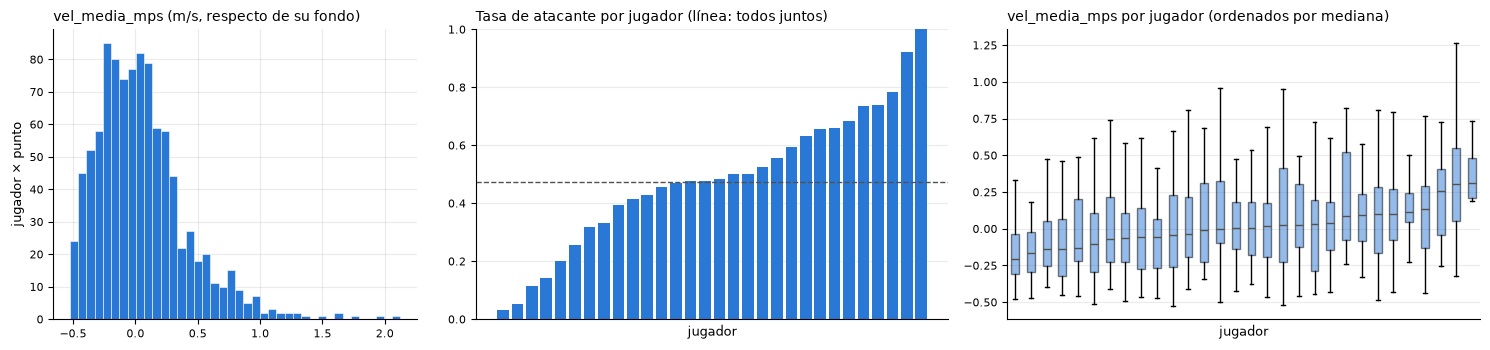

In [23]:
obs = dis.observaciones(participaciones)
jug = dis.por_jugador(obs)
print(f"Filas jugador × punto con video (D41): {len(obs)}, de {obs['codigo'].nunique()} jugadores | puntos por jugador: "
      f"de {jug['puntos'].min()} a {jug['puntos'].max()} (mediana {jug['puntos'].median():.0f})")
print(f'Con menos de {dis.MIN_PUNTOS} puntos (D42):', jug.loc[jug['puntos'] < dis.MIN_PUNTOS, 'nombre'].tolist())
display(obs['vel_media_mps'].describe().to_frame().T.round(3).assign(asimetria=round(obs['vel_media_mps'].skew(), 2)))
print(f"atacante: {obs['atacante'].mean():.1%} de las filas | por jugador, de {jug['tasa_atacante'].min():.0%} a {jug['tasa_atacante'].max():.0%}")

print('¿Todos los jugadores son iguales?')
display(dis.diferencias_entre_jugadores(obs))
print('Dependencias para la fase 4 (Spearman):')
display(dis.dependencias(obs).round(3))
tercios, p_tercios = dis.por_tercio(obs)
print('Por tercio del torneo:')
display(tercios.round(3))
print('¿Cambian entre tercios? p =', {k: float(f'{v:.2g}') for k, v in p_tercios.items()})
en_tercio = obs['partido'].map({p: i for i, ps in enumerate(np.array_split(np.sort(obs['partido'].unique()), 3)) for p in ps})
print('Jugadores que juegan en los 3 tercios:', int((obs.assign(t=en_tercio).groupby('codigo')['t'].nunique() == 3).sum()),
      'de', obs['codigo'].nunique())

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={'width_ratios': [1, 1.3, 1.3]})
ejes[0].hist(obs['vel_media_mps'], bins=40, edgecolor='white', linewidth=0.4)
ejes[0].set(title='vel_media_mps (m/s, respecto de su fondo)', ylabel='jugador × punto')
orden = jug.sort_values('tasa_atacante')
ejes[1].bar(range(len(orden)), orden['tasa_atacante'])
ejes[1].axhline(obs['atacante'].mean(), color='#52514e', linestyle='--', linewidth=1)
ejes[1].set(title='Tasa de atacante por jugador (línea: todos juntos)', xticks=[], xlabel='jugador', ylim=(0, 1))
orden = jug.sort_values('vel_mediana')['codigo']
ejes[2].boxplot([obs.loc[obs['codigo'] == c, 'vel_media_mps'] for c in orden], showfliers=False, patch_artist=True,
                boxprops={'facecolor': COLOR, 'alpha': 0.5}, medianprops={'color': '#52514e'})
ejes[2].set(title='vel_media_mps por jugador (ordenados por mediana)', xticks=[], xlabel='jugador')
fig.tight_layout()
plt.show()

**Resultados**
- **Datos (D41):** 979 filas jugador × punto de 30 jugadores, con 7 a 57 puntos por jugador (mediana 35). Isabella Arenas González y Jerónimo Coy tienen 7 cada uno, así que usan la global (D42).
- **`atacante`:** el 47,3 % de las filas son de atacante. Por jugador va del 3 % al 100 %, y el chi² rechaza que todos tengan la misma proporción (p < 0,001).
- **`vel_media_mps`:** va de −0,53 a 2,13 m/s, con mediana 0 (está medida respecto de su fondo) y cola a la derecha (asimetría 1,32). Kruskal-Wallis rechaza que todos los jugadores tengan la misma distribución (p < 0,001).
- **Dependencias para la fase 4:**
  - Las dos variables del mismo jugador en el mismo punto casi no se relacionan (Spearman 0,13).
  - Los compañeros se parecen: 0,44 en `atacante` y 0,22 en velocidad (482 pares).
  - Cada jugador repite su estilo de un punto al siguiente (mediana 0,46 entre 27 jugadores); en la velocidad la mediana es 0,17.
  - Por tercio del torneo, la tasa de atacante pasa de 0,43 a 0,60 y luego a 0,36, y la velocidad media de 0,09 a 0,05 y luego a 0,00 (p < 0,001 en las dos). Solo 12 de los 30 jugadores juegan en los tres tercios, así que esta comparación no separa el momento del torneo de quién juega.

### 3.2 Ajuste con todos los jugadores

**Objetivo:** encontrar la distribución de `vel_media_mps` con todos los jugadores juntos; su familia es la que usa cada jugador en la 3.3.

**Decisión (D43)**
- **`atacante`:** es 0/1, así que es Bernoulli con p = proporción de puntos como atacante. No necesita prueba de bondad.
- **`vel_media_mps`:** se ajustan por máxima verosimilitud 10 candidatas: normal, uniforme, triangular, exponencial, gamma, Erlang (gamma con forma entera), chi², lognormal, Weibull y beta. Como tiene valores negativos (está medida respecto de su fondo, D22), cada candidata lleva un desplazamiento y una escala que también se estiman.
  - **Log-verosimilitud:** mayor es mejor. **AIC** = 2k − 2 × log-verosimilitud, con k parámetros: menor es mejor.
  - **Kolmogórov-Smirnov (KS):** compara la distribución acumulada de los datos con la de la candidata; si p < 0,05, se rechaza.
  - Gana la de menor AIC entre las que KS no rechaza. Si todas se rechazan, se sortea de los datos (bootstrap empírico).

,familia,parametros,k,log_verosimilitud,AIC,p_KS
0,gamma,"a=2.92, desplazamiento=-0.572, escala=0.213",3,-276.7575,559.5150,0.4424
1,erlang,"a=3, desplazamiento=-0.577, escala=0.209",3,-276.7910,559.5819,0.4576
2,weibull,"c=1.65, desplazamiento=-0.529, escala=0.648",3,-279.3260,564.6519,0.0959
3,lognormal,"s=0.417, desplazamiento=-0.792, escala=0.772",3,-279.9076,565.8151,0.4339
4,normal,"desplazamiento=0.0494, escala=0.363",2,-397.9932,799.9864,0.0000
5,exponencial,"desplazamiento=-0.526, escala=0.576",2,-438.1370,880.2740,0.0000
6,triangular,"c=0.0286, desplazamiento=-0.533, escala=2.66",3,-531.3847,1068.7695,0.0000
7,beta,"a=0.564, b=6.4, desplazamiento=-0.526, escala=...",4,-626.8597,1261.7194,0.0000
8,chi2,"df=1.05, desplazamiento=-0.526, escala=0.658",3,-703.9757,1413.9514,0.0000
9,uniforme,"desplazamiento=-0.526, escala=2.65",2,-954.6261,1913.2521,0.0000


Elegida (D43): gamma | atacante: Bernoulli con p = 0.473
Probabilidad de la gamma por debajo del menor valor observado (-0.526 m/s): 0.18%


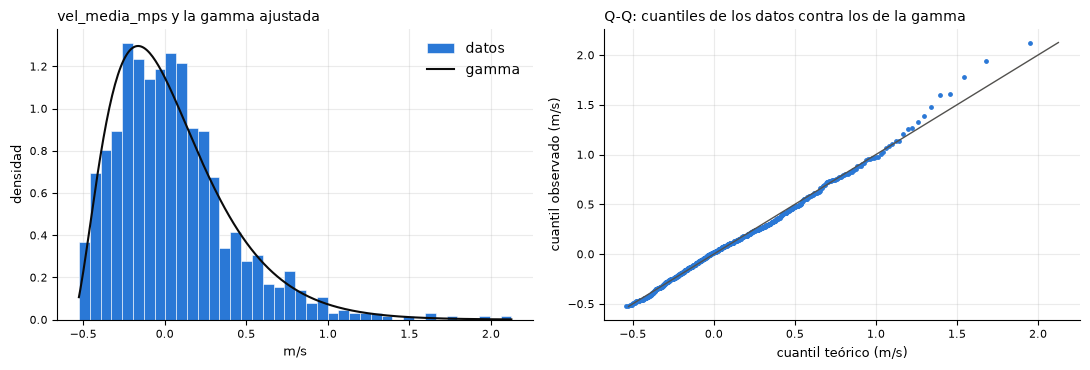

In [24]:
x = obs['vel_media_mps'].to_numpy()
candidatas = dis.comparar_candidatas(x)
display(candidatas.round(4))
familia = dis.elegir(candidatas)
print(f"Elegida (D43): {familia or 'ninguna, bootstrap empírico'} | atacante: Bernoulli con p = {obs['atacante'].mean():.3f}")

if familia:
    dist_global, _ = dis.ajustar(x, familia)
    print(f'Probabilidad de la {familia} por debajo del menor valor observado ({x.min():.3f} m/s): {dist_global.cdf(x.min()):.2%}')
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
    xs = np.linspace(x.min(), x.max(), 300)
    ejes[0].hist(x, bins=40, density=True, edgecolor='white', linewidth=0.4, label='datos')
    ejes[0].plot(xs, dist_global.pdf(xs), color='#0b0b0b', linewidth=1.5, label=familia)
    ejes[0].legend(frameon=False)
    ejes[0].set(title=f'vel_media_mps y la {familia} ajustada', xlabel='m/s', ylabel='densidad')
    q = (np.arange(1, len(x) + 1) - 0.5) / len(x)
    ejes[1].scatter(dist_global.ppf(q), np.sort(x), s=6)
    ejes[1].plot([x.min(), x.max()], [x.min(), x.max()], color='#52514e', linewidth=1)
    ejes[1].set(title=f'Q-Q: cuantiles de los datos contra los de la {familia}', xlabel='cuantil teórico (m/s)',
                ylabel='cuantil observado (m/s)')
    fig.tight_layout()
    plt.show()

**Resultados**
- **Gana la gamma** (forma 2,92; desplazamiento −0,572; escala 0,213): tiene el menor AIC (559,5) y KS no la rechaza (p = 0,44).
- La Erlang (forma 3) queda casi igual (AIC 559,6; p = 0,46). La Weibull (564,7; p = 0,10) y la lognormal (565,8; p = 0,43) también pasan, pero con más AIC.
- La normal, la exponencial, la triangular, la beta, la chi² y la uniforme se rechazan (p < 0,001).
- La gamma pone el 0,18 % de su probabilidad por debajo del menor valor observado (−0,526 m/s).
- En el Q-Q los puntos siguen la recta salvo en la cola alta: por encima de unos 1,2 m/s los datos quedan por encima, o sea, hay valores un poco más altos de los que da la gamma.
- **`atacante`:** Bernoulli con p = 0,473.

### 3.3 Ajuste por jugador y tabla para la fase 4

**Objetivo:** dejar lista, para cada jugador, la distribución de sus dos variables.

**Decisión (D44)**
- `atacante`: Bernoulli con la proporción del jugador.
- `vel_media_mps`: la familia de la 3.2 con el mismo desplazamiento para todos y la forma y la escala de cada jugador. Si KS la rechaza en un jugador, se sortea de sus propios valores (bootstrap empírico).
- Con menos de 10 puntos, las dos variables van con la global (D42).
- **Revisión:** para cada jugador se saca el intervalo del 95 % del percentil 90 de sus datos (bootstrap de sus puntos, 1.000 muestras, semilla 2026) y se mira si el percentil 90 de su distribución cae adentro. El percentil 90 mide la cola, que es donde más se diferencian las distribuciones.

,codigo,nombre,puntos,origen,p_atacante,metodo_vel,familia_vel,p_KS_vel,p90_obs,p90_IC95,p90_dist,p90_en_IC
0,099999,Jorge García,23,jugador,0.739,parametrica,gamma,0.681,0.721,[0.337; 1.047],0.754,True
1,107568,Jose Fabian Garcia Camargo,33,jugador,0.394,parametrica,gamma,0.936,0.557,[0.207; 0.752],0.523,True
2,193095,Marcela Velásquez,32,jugador,0.031,parametrica,gamma,0.807,0.565,[0.210; 0.726],0.488,True
3,196393,Juan Andrés Ordóñez Vanegas,38,jugador,0.500,parametrica,gamma,0.582,0.576,[0.127; 0.734],0.494,True
4,199884,Juliana Gómez,40,jugador,0.475,parametrica,gamma,0.766,0.302,[0.237; 0.668],0.529,True
5,260189,Valentina Rodríguez Zuluaga,30,jugador,0.633,parametrica,gamma,0.959,0.790,[0.553; 1.261],0.883,True
6,283321,Santiago Pujol Zabala,35,jugador,0.114,parametrica,gamma,0.617,0.422,[0.316; 0.494],0.522,False
7,323614,Gabriel Armando González Sosa,45,jugador,0.200,parametrica,gamma,0.932,0.216,[-0.004; 0.512],0.210,True
8,324764,Laura Sofía Rodríguez González,23,jugador,0.783,parametrica,gamma,0.760,0.649,[0.295; 1.837],0.717,True
9,326450,Ana Sofía Santander Prieto,18,jugador,0.556,parametrica,gamma,0.948,0.627,[0.072; 1.134],0.575,True


Jugadores por método (vel_media_mps): {'parametrica': 28, 'global': 2}
Percentil 90 de su distribución dentro del intervalo de sus datos: 27 de 28


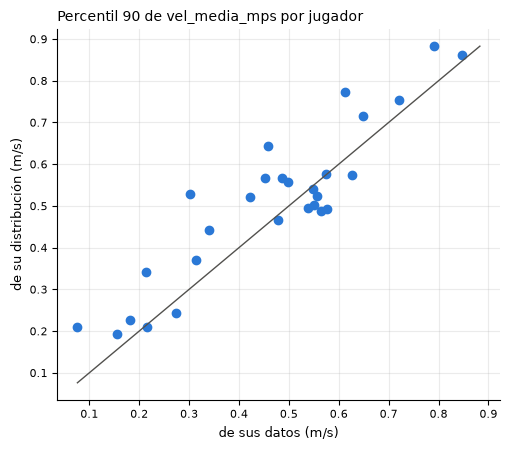

Guardado: data\interim\distribuciones_jugador.csv | la tabla leída reconstruye cada distribución: True


In [25]:
distribuciones_jugador = dis.ajustar_por_jugador(obs, familia)
display(distribuciones_jugador.drop(columns=['scipy_vel', 'parametros_vel']).round(3))
print('Jugadores por método (vel_media_mps):', distribuciones_jugador['metodo_vel'].value_counts().to_dict())
ajustados = distribuciones_jugador[distribuciones_jugador['metodo_vel'] == 'parametrica']
print(f"Percentil 90 de su distribución dentro del intervalo de sus datos: {int(ajustados['p90_en_IC'].sum())} de {len(ajustados)}")

fig, eje = plt.subplots(figsize=(5.2, 4.6))
eje.scatter(ajustados['p90_obs'], ajustados['p90_dist'])
lim = [ajustados[['p90_obs', 'p90_dist']].min().min(), ajustados[['p90_obs', 'p90_dist']].max().max()]
eje.plot(lim, lim, color='#52514e', linewidth=1)
eje.set(title='Percentil 90 de vel_media_mps por jugador', xlabel='de sus datos (m/s)', ylabel='de su distribución (m/s)')
fig.tight_layout()
plt.show()

ruta = datos.guardar_tabla(distribuciones_jugador, 'distribuciones_jugador')
leida = pd.read_csv(ruta, dtype={'codigo': str})
reconstruye = all(np.isclose(dis.distribucion_vel(f).ppf(0.9), f['p90_dist']) for _, f in leida.iterrows() if dis.distribucion_vel(f))
print('Guardado:', ruta.relative_to(RAIZ), '| la tabla leída reconstruye cada distribución:', reconstruye)

**Resultados**
- **`vel_media_mps` (D44):** los 28 jugadores con 10 puntos o más quedan con su propia gamma; KS no la rechaza en ninguno (p de 0,19 a 1,00). Nadie va por bootstrap.
- **Revisión:** en 27 de los 28, el percentil 90 de su gamma cae dentro del intervalo del 95 % de sus datos. Santiago Pujol Zabala queda por fuera: 0,52 m/s en su gamma contra [0,32; 0,49] en sus datos.
- **`atacante`:** la proporción va de 0,03 (Marcela Velásquez) a 0,92 (David Jerónimo Rojas).
- **Los 2 con 7 puntos (D42)** usan p = 0,473 y la gamma de todos. En sus 7 puntos, Jerónimo Coy fue atacante en todos e Isabella Arenas en 1, y los dos tienen un percentil 90 de velocidad (0,68 y 0,81 m/s) más alto que el de la global (0,54).
- Se guardó en `data/interim/distribuciones_jugador.csv`. Leída de nuevo, reconstruye la distribución de cada jugador.